In [44]:
# ============================================================
# MICROWAVE CAVITY ANALYSIS
# ============================================================
#
# Analytical and numerical investigation of:
#
#   1. Cylindrical TM010 cavity
#   2. Cylindrical TM110 cavity
#   3. Square rectangular TM210 cavity
#
# The notebook uses:
#   SymPy   -> symbolic mathematics and analytical integrals
#   NumPy   -> numerical arrays and evaluation
#   SciPy   -> Bessel-function roots
#   Matplotlib -> field visualisation
#
# All fields are represented as phasor amplitudes.
#
# The unloaded cavity Q is calculated from:
#
#       Q0 = omega * W / Pc
#
# where
#
#       W = We + Wm
#
# and
#
#       Pc = Rs/2 * integral_S |Ht|^2 dS
#
# The loaded Q due to probes, samples, etc. is deliberately
# treated separately.
# ============================================================

import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

from scipy.special import jv, jvp, jn_zeros

from IPython.display import display, Math, Markdown

# SymPy display
sp.init_printing()

# Numerical constants
mu0 = 4 * np.pi * 1e-7
eps0 = 8.8541878128e-12
c0 = 1 / np.sqrt(mu0 * eps0)

# Bessel roots useful for the cylindrical cavities
x01 = jn_zeros(0, 1)[0]
x11 = jn_zeros(1, 1)[0]

print(f"x_01 = {x01:.12f}")
print(f"x_11 = {x11:.12f}")
print(f"c0   = {c0:.6e} m/s")

x_01 = 2.404825557696
x_11 = 3.831705970208
c0   = 2.997925e+08 m/s


In [45]:
# ============================================================
# SYMBOLIC VARIABLES
# ============================================================

# Geometrical variables
a, b, c, r, x, y, z, theta = sp.symbols(
    'a b c r x y z theta',
    positive=True,
    real=True
)

# Mode/wave variables
k, omega = sp.symbols(
    'k omega',
    positive=True,
    real=True
)

# Material parameters
mu, eps, sigma, Rs = sp.symbols(
    'mu epsilon sigma R_s',
    positive=True,
    real=True
)

# Field amplitude
A = sp.symbols('A', positive=True, real=True)

# Bessel-function radial coordinate
u = sp.symbols('u', positive=True, real=True)

# Convenient symbolic notation
pi = sp.pi
j = sp.I

In [46]:
# ============================================================
# BASIC ELECTROMAGNETIC RELATIONSHIPS
# ============================================================

# Resonance relationship for a homogeneous cavity:
#
#       k^2 = omega^2 * mu * eps
#
# For the modes considered here, k is the transverse
# wavenumber because there is no z variation (l = 0).

resonance_relation = sp.Eq(
    k**2,
    omega**2 * mu * eps
)

display(Math(
    r"k^2 = \omega^2\mu\epsilon"
))

# Skin depth and surface resistance for a good conductor
delta = sp.sqrt(2 / (omega * mu * sigma))

Rs_expression = sp.sqrt(omega * mu / (2 * sigma))

display(Math(
    r"\delta = \sqrt{\frac{2}{\omega\mu\sigma}}"
))

display(Math(
    r"R_s = \sqrt{\frac{\omega\mu}{2\sigma}}"
))

# Stored energies
We_general = sp.Rational(1, 4) * eps * sp.Symbol('E_integral')
Wm_general = sp.Rational(1, 4) * mu * sp.Symbol('H_integral')

display(Math(
    r"W_e = \frac{1}{4}\int_V \epsilon|\mathbf{E}|^2\,dV"
))

display(Math(
    r"W_m = \frac{1}{4}\int_V \mu|\mathbf{H}|^2\,dV"
))

display(Math(
    r"Q_0 = \frac{\omega(W_e+W_m)}{P_c}"
))

display(Math(
    r"P_c = \frac{R_s}{2}\int_S |\mathbf{H}_t|^2\,dS"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [47]:
# ============================================================
# HELPER FUNCTION FOR LATEX OUTPUT
# ============================================================

def show_equation(expr, label=None):
    """
    Display a SymPy expression as a LaTeX equation.

    Parameters
    ----------
    expr : sympy expression or equality
        Expression to display.
    label : str, optional
        Text label displayed above the equation.
    """
    
    if label:
        display(Markdown(f"### {label}"))
    
    display(Math(sp.latex(expr)))

In [48]:
# ============================================================
# CYLINDRICAL TM010 CAVITY
# ============================================================
#
# Mode:
#
#       TM_010
#
# Cylindrical notation:
#
#       p = 0
#       q = 1
#       s = 0
#
# Therefore:
#
#       k a = x_01
#
# where x_01 is the first zero of J_0.
#
# Since this is a TM mode:
#
#       B = 0
# ============================================================

k_010 = sp.Symbol('k_010', positive=True, real=True)

# Radial field functions
Ez_010 = A * sp.besselj(0, k_010 * r)

Er_010 = sp.Integer(0)
Eth_010 = sp.Integer(0)

Hr_010 = sp.Integer(0)

Hth_010 = (
    -j * omega * eps / k_010**2
    * A * sp.diff(sp.besselj(0, k_010*r), r)
)

Hz_010 = sp.Integer(0)

# Replace derivative with J_0'(kr) notation if desired
display(Markdown("### TM$_{010}$ field functions"))

show_equation(sp.Eq(sp.Symbol('E_r'), Er_010))
show_equation(sp.Eq(sp.Symbol('E_\theta'), Eth_010))
show_equation(sp.Eq(sp.Symbol('E_z'), Ez_010))

show_equation(sp.Eq(sp.Symbol('H_r'), Hr_010))
show_equation(sp.Eq(sp.Symbol('H_\theta'), Hth_010))
show_equation(sp.Eq(sp.Symbol('H_z'), Hz_010))

display(Markdown(
    r"""
The radial eigenvalue is

\[
k_{010}a=x_{01},
\]

where \(x_{01}\) is the first zero of \(J_0\).
"""
))


### TM$_{010}$ field functions

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


The radial eigenvalue is

\[
k_{010}a=x_{01},
\]

where \(x_{01}\) is the first zero of \(J_0\).


In [49]:
# ============================================================
# TM010 RESONANT FREQUENCY
# ============================================================

k_010_expr = x01 / a

omega_010_expr = k_010_expr / sp.sqrt(mu * eps)

f_010_expr = sp.simplify(
    omega_010_expr / (2 * sp.pi)
)

display(Markdown("### TM$_{010}$ resonant frequency"))

show_equation(
    sp.Eq(
        sp.Symbol(r'k_{010}'),
        k_010_expr
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'\omega_{010}'),
        omega_010_expr
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'f_{010}'),
        f_010_expr
    )
)

### TM$_{010}$ resonant frequency

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [50]:
# ============================================================
# TM010 ELECTRIC STORED ENERGY
# ============================================================

theta_integral_010 = sp.integrate(
    1,
    (theta, 0, 2*pi)
)

z_integral_010 = sp.integrate(
    1,
    (z, 0, c)
)

radial_integral_010 = sp.integrate(
    r * sp.besselj(0, k_010*r)**2,
    (r, 0, a)
)

E_integral_010 = sp.simplify(
    theta_integral_010
    * z_integral_010
    * radial_integral_010
    * A**2
)

We_010 = sp.simplify(
    sp.Rational(1, 4) * eps * E_integral_010
)

display(Markdown(
    "### TM$_{010}$ electric energy integral"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'\int_V |\mathbf{E}|^2 dV'),
        E_integral_010
    )
)

display(Markdown(
    r"""
Using the boundary condition

\[
J_0(k a)=J_0(x_{01})=0,
\]

the radial integral becomes

\[
\int_0^a rJ_0^2(kr)\,dr
=
\frac{a^2}{2}J_1^2(x_{01}).
\]
"""
))

# Substitute the root condition manually
We_010_closed = (
    sp.pi * eps * c * a**2 * A**2
    * sp.besselj(1, k_010*a)**2
    / 4
)

show_equation(
    sp.Eq(
        sp.Symbol(r'W_{e,010}'),
        We_010_closed
    )
)

### TM$_{010}$ electric energy integral

<IPython.core.display.Math object>


Using the boundary condition

\[
J_0(k a)=J_0(x_{01})=0,
\]

the radial integral becomes

\[
\int_0^a rJ_0^2(kr)\,dr
=
\frac{a^2}{2}J_1^2(x_{01}).
\]


<IPython.core.display.Math object>

In [51]:
# ============================================================
# TM010 MAGNETIC STORED ENERGY
# ============================================================

# Use the identity:
#
# J_0'(x) = -J_1(x)
#
# Therefore:
#
# |H_theta|^2 =
# (omega eps A / k)^2 J_1^2(kr)

H_integral_010 = sp.integrate(
    r * sp.besselj(1, k_010*r)**2,
    (r, 0, a)
)

H_volume_integral_010 = (
    2*pi*c
    * (omega*eps*A/k_010)**2
    * H_integral_010
)

Wm_010 = sp.simplify(
    sp.Rational(1, 4)
    * mu
    * H_volume_integral_010
)

display(Markdown(
    "### TM$_{010}$ magnetic energy"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'W_{m,010}'),
        Wm_010
    )
)

#Use the boundary condition once again of J0(k_010*a)=0
Wm_010_closed = (pi*mu*c*(A*eps*omega*a)**2 *sp.besselj(1,k_010*a)**2 /(4*k_010**2))
show_equation(sp.Eq(sp.Symbol(r'Wm_{m,010}'), Wm_010_closed))


### TM$_{010}$ magnetic energy

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [52]:
# ============================================================
# TM010 CONDUCTOR LOSS
# ============================================================
#
# Pc = Rs/2 * integral_S |Ht|^2 dS
#
# There are two contributions:
#
#   1. cylindrical side wall
#   2. top and bottom end plates
# ============================================================

# Magnitude squared of H_theta:
Htheta_sq_010 = (
    (omega * eps * A / k_010)**2
    * sp.besselj(1, k_010*r)**2
)

# ------------------------------------------------------------
# Cylindrical side wall: r = a
# ------------------------------------------------------------

I_side_010 = sp.simplify(
    2*pi*c*a
    * Htheta_sq_010.subs(r, a)
)

# ------------------------------------------------------------
# End plates: z = 0 and z = c
# ------------------------------------------------------------

I_end_one_010 = sp.integrate(
    2*pi * r * Htheta_sq_010,
    (r, 0, a)
)

I_ends_010 = sp.simplify(
    2 * I_end_one_010
)

# Apply the boundary condition J0(k_010 a) = 0
I_ends_010 = sp.simplify(
    I_ends_010.subs(sp.besselj(0, k_010*a), 0)
)

I_surface_010 = sp.simplify(
    I_side_010 + I_ends_010
)

Pc_010 = sp.simplify(
    Rs / 2 * I_surface_010
)

display(Markdown(
    "### TM$_{010}$ conductor-loss integral"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'I_{ends}'), I_ends_010
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'I_{side}'), I_side_010
    )
)
show_equation(
    sp.Eq(
        sp.Symbol(r'I_{S,010}'),
        I_surface_010
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'P_{c,010}'),
        Pc_010
    )
)

# ============================================================
# TM010 UNLOADED Q
# ============================================================

Wtotal_010 = sp.simplify(
    2 * We_010_closed
)

Q_010 = sp.simplify(
    omega * Wtotal_010 / Pc_010
)

display(Markdown(
    "### Analytical unloaded $Q_0$ for TM$_{010}$"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'Q_{0,010}'),
        Q_010
    )
)

display(Markdown(
    r"""
Eliminating \(k_{010}\) via the dispersion relation
\(k_{010}=\omega\sqrt{\mu\epsilon}\) (substituted mechanically,
not retyped by hand) collapses the amplitude and Bessel-function
factors:
"""
))

# Two-step substitution eliminates k_010 in favour of omega
Q_010_final = sp.simplify(
    Q_010.subs(omega, k_010/sp.sqrt(mu*eps))
)
Q_010_final = sp.simplify(
    Q_010_final.subs(k_010, omega*sp.sqrt(mu*eps))
)

show_equation(
    sp.Eq(
        sp.Symbol(r'Q_{0,010}'),
        Q_010_final
    )
)

# Self-check against the known closed form for a TM_np0 pillbox mode
assert sp.simplify(
    Q_010_final - omega*mu*a*c/(2*Rs*(a+c))
) == 0, "TM010 Q0 does not match the expected closed form!"


### TM$_{010}$ conductor-loss integral

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Analytical unloaded $Q_0$ for TM$_{010}$

<IPython.core.display.Math object>


Eliminating \(k_{010}\) via the dispersion relation
\(k_{010}=\omega\sqrt{\mu\epsilon}\) (substituted mechanically,
not retyped by hand) collapses the amplitude and Bessel-function
factors:


<IPython.core.display.Math object>

In [53]:
# ============================================================
# CYLINDRICAL TM110 CAVITY
# ============================================================
#
# Mode:
#
#       TM_110
#
# Therefore:
#
#       p = 1
#       q = 1
#       s = 0
#
# k a = x_11
#
# where x_11 is the first zero of J_1.
# ============================================================

k_110 = sp.Symbol('k_110', positive=True, real=True)

Ez_110 = (
    A * sp.besselj(1, k_110*r)
    * sp.cos(theta)
)

Er_110 = sp.Integer(0)
Eth_110 = sp.Integer(0)

Hr_110 = (
    -j * omega * eps
    / (k_110**2 * r)
    * A * sp.besselj(1, k_110*r)
    * sp.sin(theta)
)

Hth_110 = (
    -j * omega * eps / k_110**2
    * A * sp.diff(
        sp.besselj(1, k_110*r),
        r
    )
    * sp.cos(theta)
)

Hz_110 = sp.Integer(0)

display(Markdown("### TM$_{110}$ field functions"))

show_equation(sp.Eq(sp.Symbol('E_r'), Er_110))
show_equation(sp.Eq(sp.Symbol('E_\theta'), Eth_110))
show_equation(sp.Eq(sp.Symbol('E_z'), Ez_110))

show_equation(sp.Eq(sp.Symbol('H_r'), Hr_110))
show_equation(sp.Eq(sp.Symbol('H_\theta'), Hth_110))
show_equation(sp.Eq(sp.Symbol('H_z'), Hz_110))


### TM$_{110}$ field functions

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [54]:
# ============================================================
# TM110 RESONANT FREQUENCY
# ============================================================

k_110_expr = x11 / a

omega_110_expr = k_110_expr / sp.sqrt(mu * eps)

f_110_expr = sp.simplify(
    omega_110_expr / (2*pi)
)

display(Markdown("### TM$_{110}$ resonant frequency"))

show_equation(
    sp.Eq(
        sp.Symbol(r'k_{110}'),
        k_110_expr
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'f_{110}'),
        f_110_expr
    )
)

### TM$_{110}$ resonant frequency

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [55]:
# ============================================================
# TM110 ELECTRIC STORED ENERGY
# ============================================================

# |Ez|^2 contains cos^2(theta)

theta_factor_110 = sp.integrate(
    sp.cos(theta)**2,
    (theta, 0, 2*pi)
)

radial_integral_110 = sp.integrate(
    r * sp.besselj(1, k_110*r)**2,
    (r, 0, a)
)

E_integral_110 = sp.simplify(
    A**2
    * c
    * theta_factor_110
    * radial_integral_110
)

We_110 = sp.simplify(
    eps * E_integral_110 / 4
)

display(Markdown(
    "### TM$_{110}$ electric energy"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'W_{e,110}'),
        We_110
    )
)

We_110_closed = (
    pi * eps * c * a**2 * A**2
    * sp.besselj(0, k_110*a)**2
    / 8
)

show_equation(
    sp.Eq(
        sp.Symbol(r'W_{e,110}'),
        We_110_closed
    )
)

### TM$_{110}$ electric energy

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [56]:
# ============================================================
# TM110 MAGNETIC STORED ENERGY
# ============================================================
#
# |H|^2 = |Hr|^2 + |Htheta|^2
#
# The angular dependence gives:
#
#   integral sin^2(theta) dtheta = pi
#   integral cos^2(theta) dtheta = pi
# ============================================================

H2_110 = sp.simplify(Hr_110*sp.conjugate(Hr_110)+Hth_110*sp.conjugate(Hth_110))

show_equation(sp.Eq(sp.Symbol('H^2'), H2_110))

Wm_110_raw = sp.Rational(1,4)*mu*c*sp.integrate(H2_110*r, (theta,0,2*pi), (r,0,a))

display(Markdown(
    "### TM$_{110}$ magnetic energy"
))

show_equation(sp.Eq(sp.Symbol(r'W_{m,110}'), sp.simplify(Wm_110_raw)))

# Apply the boundary condition J1(k_110 a) = 0
Wm_110_closed = sp.simplify(
    Wm_110_raw.subs(sp.besselj(1, k_110*a), 0)
)

show_equation(sp.Eq(sp.Symbol(r'W_{m,110}'), Wm_110_closed))

# Self-check: the energy theorem requires We_110 = Wm_110 at resonance
_check_110 = sp.simplify(
    (We_110_closed - Wm_110_closed).subs(omega**2, k_110**2/(mu*eps))
)
assert _check_110 == 0, "TM110: We != Wm at resonance!"


<IPython.core.display.Math object>

### TM$_{110}$ magnetic energy

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [57]:
# ============================================================
# TM110 CONDUCTOR LOSS
# ============================================================
#
# The cavity surface consists of:
#
#   1. cylindrical wall
#   2. top end plate
#   3. bottom end plate
# ============================================================

# ------------------------------------------------------------
# Cylindrical wall
# ------------------------------------------------------------

# At r = a, J1(k a) = 0, so Hr = 0.
#
# Only Htheta contributes.

Htheta_sq_110 = (
    (omega * eps * A / k_110**2)**2
    * sp.diff(
        sp.besselj(1, k_110*r),
        r
    )**2
    * sp.cos(theta)**2
)

I_side_110 = sp.simplify(
    sp.integrate(
        Htheta_sq_110.subs(r, a) * a,
        (theta, 0, 2*pi)
    ) * c
)

# Apply the boundary condition J1(k_110 a) = 0
I_side_110 = sp.simplify(
    I_side_110.subs(sp.besselj(1, k_110*a), 0)
)

# ------------------------------------------------------------
# End plates
# ------------------------------------------------------------

Hr_sq_110 = (
    (omega * eps * A)**2
    / (k_110**4 * r**2)
    * sp.besselj(1, k_110*r)**2
    * sp.sin(theta)**2
)

Htheta_sq_end_110 = Htheta_sq_110

I_one_end_110 = sp.integrate(
    sp.integrate(
        (Hr_sq_110 + Htheta_sq_end_110) * r,
        (theta, 0, 2*pi)
    ),
    (r, 0, a)
)

I_ends_110 = sp.simplify(
    2 * I_one_end_110
)

# Apply the boundary condition J1(k_110 a) = 0
I_ends_110 = sp.simplify(
    I_ends_110.subs(sp.besselj(1, k_110*a), 0)
)

I_surface_110 = sp.simplify(
    I_side_110 + I_ends_110
)

Pc_110 = sp.simplify(
    Rs / 2 * I_surface_110
)

display(Markdown(
    "### TM$_{110}$ wall-loss integral"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'I_{S,110}'),
        I_surface_110
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'P_{c,110}'),
        Pc_110
    )
)

# ============================================================
# TM110 UNLOADED Q
# ============================================================

Wtotal_110 = 2 * We_110_closed

Q_110 = sp.simplify(
    omega * Wtotal_110 / Pc_110
)

display(Markdown(
    "### Analytical unloaded $Q_0$ for TM$_{110}$"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'Q_{0,110}'),
        Q_110
    )
)

display(Markdown(
    r"""
Eliminating \(k_{110}\) via the dispersion relation
\(k_{110}=\omega\sqrt{\mu\epsilon}\) (substituted mechanically):
"""
))

Q_110_final = sp.simplify(
    Q_110.subs(omega, k_110/sp.sqrt(mu*eps))
)
Q_110_final = sp.simplify(
    Q_110_final.subs(k_110, omega*sp.sqrt(mu*eps))
)

show_equation(
    sp.Eq(
        sp.Symbol(r'Q_{0,110}'),
        Q_110_final
    )
)

# Self-check against the known closed form
assert sp.simplify(
    Q_110_final - omega*mu*a*c/(2*Rs*(a+c))
) == 0, "TM110 Q0 does not match the expected closed form!"


### TM$_{110}$ wall-loss integral

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Analytical unloaded $Q_0$ for TM$_{110}$

<IPython.core.display.Math object>


Eliminating \(k_{110}\) via the dispersion relation
\(k_{110}=\omega\sqrt{\mu\epsilon}\) (substituted mechanically):


<IPython.core.display.Math object>

In [58]:
# ============================================================
# SQUARE RECTANGULAR TM210 CAVITY
# ============================================================
#
# General rectangular notation:
#
#       TM_pqr
#
# For TM210:
#
#       p = 2
#       q = 1
#       r = 0
#
# Square cavity:
#
#       a = b
#
# Therefore:
#
#       k^2 = (2*pi/a)^2 + (pi/a)^2
#           = 5*pi^2/a^2
#
#       k = sqrt(5)*pi/a
#
# Since this is a TM mode:
#
#       B = 0
# ============================================================

k_210 = sp.sqrt(5) * pi / a

Ez_210 = (
    A
    * sp.sin(2*pi*x/a)
    * sp.sin(pi*y/a)
)

Ex_210 = sp.Integer(0)
Ey_210 = sp.Integer(0)

Hx_210 = (
    j * omega * eps * A * a
    / (5*pi)
    * sp.sin(2*pi*x/a)
    * sp.cos(pi*y/a)
)

Hy_210 = (
    -j * 2 * omega * eps * A * a
    / (5*pi)
    * sp.cos(2*pi*x/a)
    * sp.sin(pi*y/a)
)

Hz_210 = sp.Integer(0)

display(Markdown("### TM$_{210}$ square-cavity field functions"))

show_equation(sp.Eq(sp.Symbol('E_x'), Ex_210))
show_equation(sp.Eq(sp.Symbol('E_y'), Ey_210))
show_equation(sp.Eq(sp.Symbol('E_z'), Ez_210))

show_equation(sp.Eq(sp.Symbol('H_x'), Hx_210))
show_equation(sp.Eq(sp.Symbol('H_y'), Hy_210))
show_equation(sp.Eq(sp.Symbol('H_z'), Hz_210))


### TM$_{210}$ square-cavity field functions

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [59]:
# ============================================================
# TM210 RESONANT FREQUENCY
# ============================================================

omega_210_expr = sp.simplify(
    k_210 / sp.sqrt(mu * eps)
)

f_210_expr = sp.simplify(
    omega_210_expr / (2*pi)
)

display(Markdown("### TM$_{210}$ resonant frequency"))

show_equation(
    sp.Eq(
        sp.Symbol(r'k_{210}'),
        k_210
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'f_{210}'),
        f_210_expr
    )
)

### TM$_{210}$ resonant frequency

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [60]:
# ============================================================
# TM210 ELECTRIC STORED ENERGY
# ============================================================

E2_210 = Ez_210**2

E_integral_210 = sp.integrate(
    sp.integrate(
        sp.integrate(
            E2_210,
            (x, 0, a)
        ),
        (y, 0, a)
    ),
    (z, 0, c)
)

We_210 = sp.simplify(
    eps * E_integral_210 / 4
)

display(Markdown(
    "### TM$_{210}$ electric energy"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'\int_V|\mathbf E|^2dV'),
        E_integral_210
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'W_{e,210}'),
        We_210
    )
)

### TM$_{210}$ electric energy

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [61]:
# ============================================================
# TM210 MAGNETIC STORED ENERGY
# ============================================================

H2_210 = (
    sp.expand_complex(Hx_210 * sp.conjugate(Hx_210))
    +
    sp.expand_complex(Hy_210 * sp.conjugate(Hy_210))
)

# Since A, omega, eps are declared real and positive,
# simplify the expression.

H2_210 = sp.simplify(H2_210)

H_integral_210 = sp.integrate(
    sp.integrate(
        sp.integrate(
            H2_210,
            (x, 0, a)
        ),
        (y, 0, a)
    ),
    (z, 0, c)
)

Wm_210 = sp.simplify(
    mu * H_integral_210 / 4
)

display(Markdown(
    "### TM$_{210}$ magnetic energy"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'W_{m,210}'),
        Wm_210
    )
)

display(Markdown(
    r"""
At resonance,

\[
k^2=\omega^2\mu\epsilon,
\]

and the result should satisfy

\[
W_{m,210}=W_{e,210}.
\]
"""
))

# Self-check: substitute the resonance condition and compare to We_210
_Wm_210_res = sp.simplify(
    Wm_210.subs(omega**2, k_210**2/(mu*eps))
)
assert sp.simplify(_Wm_210_res - We_210) == 0, "TM210: We != Wm at resonance!"


### TM$_{210}$ magnetic energy

<IPython.core.display.Math object>


At resonance,

\[
k^2=\omega^2\mu\epsilon,
\]

and the result should satisfy

\[
W_{m,210}=W_{e,210}.
\]


In [62]:
# ============================================================
# TM210 CONDUCTOR LOSS
# ============================================================
#
# Six faces:
#
#   x = 0
#   x = a
#   y = 0
#   y = a
#   z = 0
#   z = c
#
# On each face only the magnetic-field components tangential
# to that face contribute to conductor loss.
# ============================================================

Hx_sq_210 = sp.simplify(
    Hx_210 * sp.conjugate(Hx_210)
)

Hy_sq_210 = sp.simplify(
    Hy_210 * sp.conjugate(Hy_210)
)

# ------------------------------------------------------------
# x = 0 and x = a
# ------------------------------------------------------------
#
# Tangential magnetic field:
#
#       Ht = Hy
#
# evaluated ON each face (not integrated over x).
# ------------------------------------------------------------

I_x_faces = sp.simplify(
    sp.integrate(
        Hy_sq_210.subs(x, 0),
        (y, 0, a), (z, 0, c)
    )
    +
    sp.integrate(
        Hy_sq_210.subs(x, a),
        (y, 0, a), (z, 0, c)
    )
)

# ------------------------------------------------------------
# y = 0 and y = a
# ------------------------------------------------------------
#
# Tangential magnetic field:
#
#       Ht = Hx
#
# ------------------------------------------------------------

I_y_faces = sp.simplify(
    sp.integrate(
        Hx_sq_210.subs(y, 0),
        (x, 0, a), (z, 0, c)
    )
    +
    sp.integrate(
        Hx_sq_210.subs(y, a),
        (x, 0, a), (z, 0, c)
    )
)

# ------------------------------------------------------------
# z = 0 and z = c
# ------------------------------------------------------------
#
# Both Hx and Hy are tangential. Neither depends on z (l=0),
# so the two end plates contribute equally.
# ------------------------------------------------------------

I_z_one = sp.integrate(
    sp.integrate(
        Hx_sq_210 + Hy_sq_210,
        (x, 0, a)
    ),
    (y, 0, a)
)

I_z_faces = sp.simplify(
    2 * I_z_one
)

# Total surface integral
I_surface_210 = sp.simplify(
    I_x_faces
    + I_y_faces
    + I_z_faces
)

Pc_210 = sp.simplify(
    Rs / 2 * I_surface_210
)

display(Markdown(
    "### TM$_{210}$ wall-loss contributions"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'I_{x\text{-faces}}'),
        I_x_faces
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'I_{y\text{-faces}}'),
        I_y_faces
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'I_{z\text{-faces}}'),
        I_z_faces
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'I_{S,210}'),
        I_surface_210
    )
)


### TM$_{210}$ wall-loss contributions

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [63]:
# ============================================================
# TM210 UNLOADED Q
# ============================================================

Wtotal_210 = sp.simplify(
    We_210 + Wm_210
)

Q_210 = sp.simplify(
    omega * Wtotal_210 / Pc_210
)

display(Markdown(
    "### Analytical unloaded $Q_0$ for TM$_{210}$"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'Q_{0,210}'),
        Q_210
    )
)

display(Markdown(
    r"""
Eliminating \(\epsilon\) via the resonance condition
\(k^2=5\pi^2/a^2=\omega^2\mu\epsilon\) (substituted mechanically):
"""
))

Q_210_final = sp.simplify(
    Q_210.subs(eps, k_210**2 / (omega**2 * mu))
)

show_equation(
    sp.Eq(
        sp.Symbol(r'Q_{0,210}'),
        Q_210_final
    )
)

# Self-check against the known closed form
assert sp.simplify(
    Q_210_final - omega*mu*a*c/(2*Rs*(a + 2*c))
) == 0, "TM210 Q0 does not match the expected closed form!"


### Analytical unloaded $Q_0$ for TM$_{210}$

<IPython.core.display.Math object>


Eliminating \(\epsilon\) via the resonance condition
\(k^2=5\pi^2/a^2=\omega^2\mu\epsilon\) (substituted mechanically):


<IPython.core.display.Math object>

In [64]:
# ============================================================
# NUMERICAL CAVITY PARAMETERS
# ============================================================
#
# Change these values to your actual cavity dimensions.
#
# All dimensions are in metres.
# ============================================================

# TM010 / TM110 cylindrical cavity
a_cyl = 0.046833       # radius [m]
c_cyl = 0.035       # height [m]

# TM210 square cavity
a_sq = 0.136807        # x/y dimension [m]
c_sq = 0.020        # height [m]

# Aluminium conductivity
sigma_al = 3.5e7    # S/m; replace with your assumed value

# Relative permeability/permittivity of empty cavity
mu_r = 1.0
eps_r = 1.0

mu_num = mu0 * mu_r
eps_num = eps0 * eps_r

# Operating frequency target
f_target = 2.45e9
omega_target = 2*np.pi*f_target

Rs_al = np.sqrt(
    omega_target * mu_num / (2*sigma_al)
)

delta_al = np.sqrt(
    2 / (omega_target * mu_num * sigma_al)
)

print(f"Aluminium surface resistance = {Rs_al:.4e} ohm")
print(f"Aluminium skin depth         = {delta_al:.4e} m")

Aluminium surface resistance = 1.6624e-02 ohm
Aluminium skin depth         = 1.7187e-06 m


In [65]:
# ============================================================
# NUMERICAL RESONANT FREQUENCIES
# ============================================================

f010_num = (
    x01 * c0
    / (2*np.pi*a_cyl)
)

f110_num = (
    x11 * c0
    / (2*np.pi*a_cyl)
)

f210_num = (
    c0 * np.sqrt(5)
    / (2*a_sq)
)

print(f"TM010 frequency = {f010_num/1e9:.6f} GHz")
print(f"TM110 frequency = {f110_num/1e9:.6f} GHz")
print(f"TM210 frequency = {f210_num/1e9:.6f} GHz")

TM010 frequency = 2.450036 GHz
TM110 frequency = 3.903741 GHz
TM210 frequency = 2.450007 GHz


C:\Users\RafIc\AppData\Local\Temp\ipykernel_8932\4258339431.py:31: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  plt.pcolormesh(


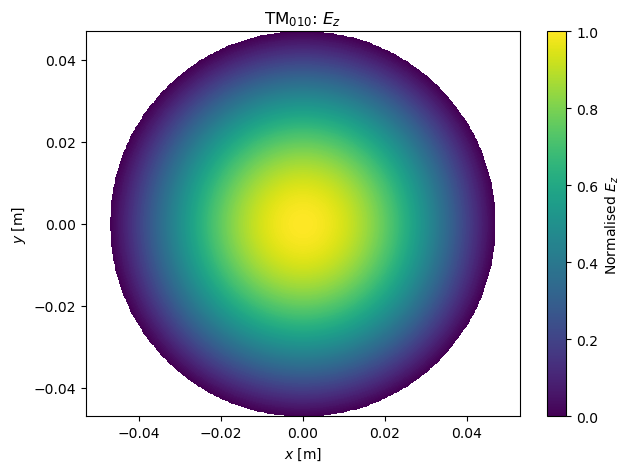

C:\Users\RafIc\AppData\Local\Temp\ipykernel_8932\4258339431.py:48: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  plt.pcolormesh(


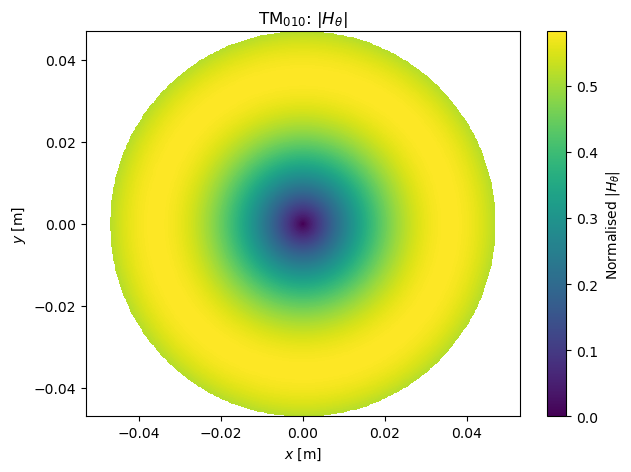

In [66]:
# ============================================================
# TM010 NUMERICAL FIELD ARRAYS
# ============================================================

Nr = 300
Ntheta = 360

r_array = np.linspace(0, a_cyl, Nr)
theta_array = np.linspace(0, 2*np.pi, Ntheta)

R, THETA = np.meshgrid(
    r_array,
    theta_array
)

k010_num = x01 / a_cyl

Ez010_num = jv(
    0,
    k010_num * R
)

Htheta010_num = jv(
    1,
    k010_num * R
)

# Plot Ez
plt.figure(figsize=(7, 5))

plt.pcolormesh(
    R * np.cos(THETA),
    R * np.sin(THETA),
    Ez010_num,
    shading='auto'
)

plt.xlabel(r'$x$ [m]')
plt.ylabel(r'$y$ [m]')
plt.title(r'TM$_{010}$: $E_z$')
plt.axis('equal')
plt.colorbar(label=r'Normalised $E_z$')
plt.show()

# Plot Htheta magnitude
plt.figure(figsize=(7, 5))

plt.pcolormesh(
    R * np.cos(THETA),
    R * np.sin(THETA),
    np.abs(Htheta010_num),
    shading='auto'
)

plt.xlabel(r'$x$ [m]')
plt.ylabel(r'$y$ [m]')
plt.title(r'TM$_{010}$: $|H_\theta|$')
plt.axis('equal')
plt.colorbar(label=r'Normalised $|H_\theta|$')
plt.show()

C:\Users\RafIc\AppData\Local\Temp\ipykernel_8932\2414866419.py:29: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  plt.pcolormesh(


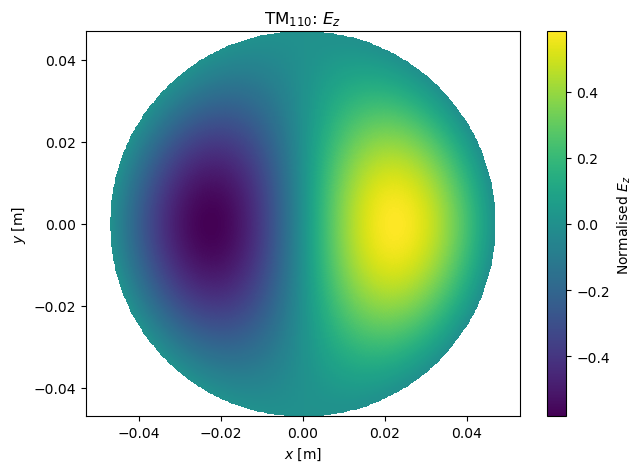

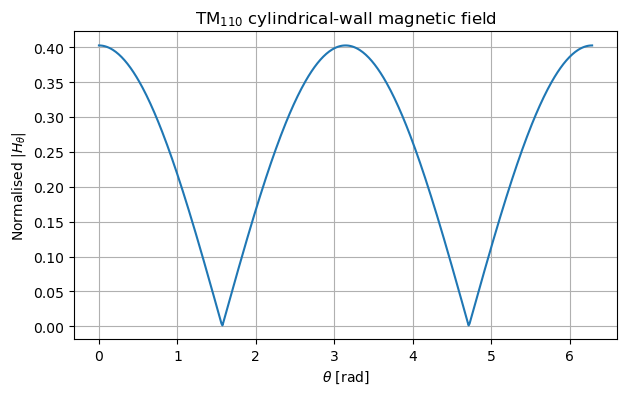

In [67]:
# ============================================================
# TM110 NUMERICAL FIELD ARRAYS
# ============================================================

k110_num = x11 / a_cyl

Ez110_num = (
    jv(1, k110_num * R)
    * np.cos(THETA)
)

Hr110_num = (
    jv(1, k110_num * R)
    / (R + 1e-15)
    * np.sin(THETA)
)

Htheta110_num = (
    jvp(1, k110_num * R)
    * np.cos(THETA)
)

# ------------------------------------------------------------
# Ez
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.pcolormesh(
    R * np.cos(THETA),
    R * np.sin(THETA),
    Ez110_num,
    shading='auto'
)

plt.xlabel(r'$x$ [m]')
plt.ylabel(r'$y$ [m]')
plt.title(r'TM$_{110}$: $E_z$')
plt.axis('equal')
plt.colorbar(label=r'Normalised $E_z$')
plt.show()

# ------------------------------------------------------------
# |H_t| on cylindrical wall
# ------------------------------------------------------------

wall_theta = np.linspace(0, 2*np.pi, 500)

Htheta_wall = (
    jvp(1, x11)
    * np.cos(wall_theta)
)

plt.figure(figsize=(7, 4))

plt.plot(
    wall_theta,
    np.abs(Htheta_wall)
)

plt.xlabel(r'$\theta$ [rad]')
plt.ylabel(r'Normalised $|H_\theta|$')
plt.title(r'TM$_{110}$ cylindrical-wall magnetic field')
plt.grid(True)
plt.show()

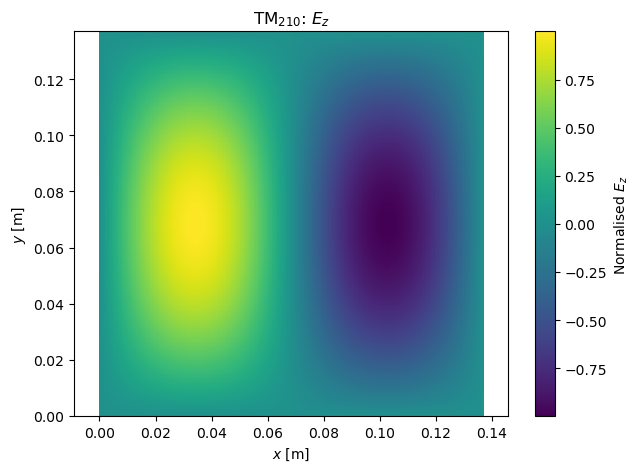

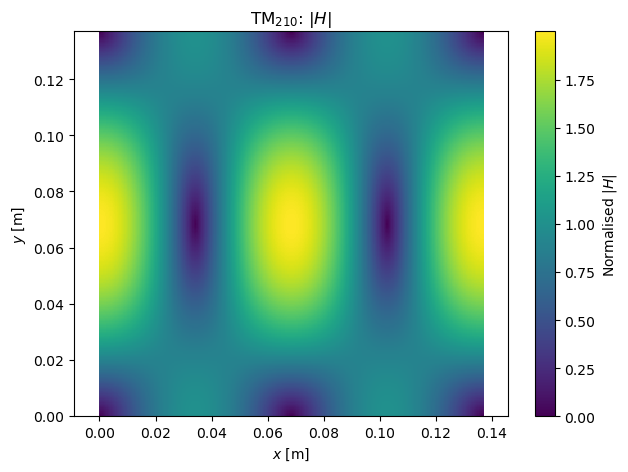

In [68]:
# ============================================================
# TM210 NUMERICAL FIELD ARRAYS
# ============================================================

N = 300

x_array = np.linspace(0, a_sq, N)
y_array = np.linspace(0, a_sq, N)

X, Y = np.meshgrid(
    x_array,
    y_array
)

Ez210_num = (
    np.sin(2*np.pi*X/a_sq)
    * np.sin(np.pi*Y/a_sq)
)

Hx210_num = (
    np.sin(2*np.pi*X/a_sq)
    * np.cos(np.pi*Y/a_sq)
)

Hy210_num = (
    -2
    * np.cos(2*np.pi*X/a_sq)
    * np.sin(np.pi*Y/a_sq)
)

Hmag210_num = np.sqrt(
    Hx210_num**2
    + Hy210_num**2
)

# ------------------------------------------------------------
# Ez
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.pcolormesh(
    X,
    Y,
    Ez210_num,
    shading='auto'
)

plt.xlabel(r'$x$ [m]')
plt.ylabel(r'$y$ [m]')
plt.title(r'TM$_{210}$: $E_z$')
plt.axis('equal')
plt.colorbar(label=r'Normalised $E_z$')
plt.show()

# ------------------------------------------------------------
# |H|
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.pcolormesh(
    X,
    Y,
    Hmag210_num,
    shading='auto'
)

plt.xlabel(r'$x$ [m]')
plt.ylabel(r'$y$ [m]')
plt.title(r'TM$_{210}$: $|H|$')
plt.axis('equal')
plt.colorbar(label=r'Normalised $|H|$')
plt.show()

In [69]:
# ============================================================
# TM010 DIMENSIONAL SENSITIVITY
# ============================================================

# Frequency:
#
#       f = x01*c0/(2*pi*a)
#
# Therefore:
#
#       df/da = -f/a
#
# and approximately:
#
#       Delta f/f = -Delta a/a

da = sp.symbols(
    r'\Delta a',
    real=True
)

f010_symbolic = (
    x01 * sp.Symbol('c_0')
    / (2*pi*a)
)

df_da_010 = sp.diff(
    f010_symbolic,
    a
)

display(Markdown(
    r"""
For TM$_{010}$,

\[
f_{010}
=
\frac{x_{01}c_0}{2\pi a}.
\]

Therefore
"""
))

show_equation(
    sp.Eq(
        sp.Symbol(r'\frac{\partial f}{\partial a}'),
        df_da_010
    )
)

display(Markdown(
    r"""
and hence, to first order,

\[
\boxed{
\frac{\Delta f}{f}
\approx
-\frac{\Delta a}{a}.
}
\]
"""
))


For TM$_{010}$,

\[
f_{010}
=
\frac{x_{01}c_0}{2\pi a}.
\]

Therefore


<IPython.core.display.Math object>


and hence, to first order,

\[
\boxed{
\frac{\Delta f}{f}
\approx
-\frac{\Delta a}{a}.
}
\]


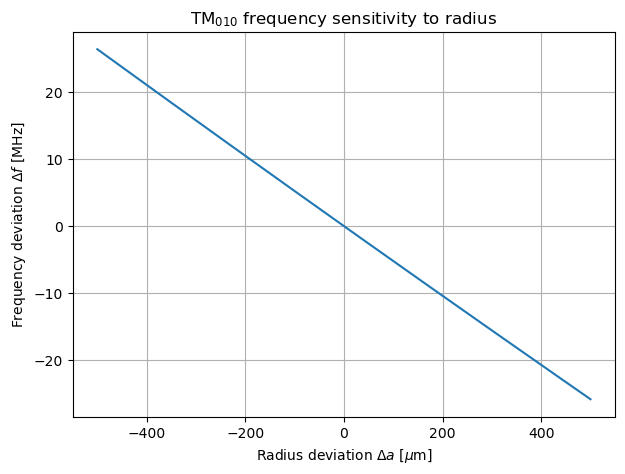

In [70]:
# ============================================================
# FREQUENCY ERROR DUE TO TM010 RADIUS ERROR
# ============================================================

# Manufacturing deviations
delta_a_values = np.linspace(
    -500e-6,
    500e-6,
    501
)

f_ideal = x01 * c0 / (2*np.pi*a_cyl)

f_perturbed = (
    x01 * c0
    / (2*np.pi*(a_cyl + delta_a_values))
)

delta_f = f_perturbed - f_ideal

plt.figure(figsize=(7, 5))

plt.plot(
    delta_a_values * 1e6,
    delta_f / 1e6
)

plt.xlabel(r'Radius deviation $\Delta a$ [$\mu$m]')
plt.ylabel(r'Frequency deviation $\Delta f$ [MHz]')
plt.title(r'TM$_{010}$ frequency sensitivity to radius')
plt.grid(True)
plt.show()

In [71]:
# ============================================================
# NUMERICAL UNLOADED Q FUNCTION
# ============================================================
#
# This function uses:
#
#       Q0 = omega * W / Pc
#
# rather than assuming the final analytical expression.
#
# This makes it useful later when additional loss terms are
# added.
# ============================================================

def cavity_Q(omega_value, W_value, Pc_value):
    """
    Calculate unloaded cavity Q.

    Parameters
    ----------
    omega_value : float
        Angular resonant frequency [rad/s].

    W_value : float
        Total stored electromagnetic energy [J].

    Pc_value : float
        Average conductor loss [W].

    Returns
    -------
    float
        Unloaded cavity quality factor.
    """
    
    return omega_value * W_value / Pc_value

# ============================================================
# ANALYTICAL Q EVALUATION
# ============================================================

# TM010
omega010_num = 2*np.pi*f010_num

Q010_num = (
    omega010_num
    * mu_num
    * a_cyl
    * c_cyl
    /
    (
        2 * Rs_al
        * (a_cyl + c_cyl)
    )
)

# TM110
omega110_num = 2*np.pi*f110_num

Q110_num = (
    omega110_num
    * mu_num
    * a_cyl
    * c_cyl
    /
    (
        2 * Rs_al
        * (a_cyl + c_cyl)
    )
)

# TM210
omega210_num = 2*np.pi*f210_num

Q210_num = (
    omega210_num
    * mu_num
    * a_sq
    * c_sq
    /
    (
        2 * Rs_al
        * (a_sq + 2*c_sq)
    )
)

print(f"TM010 unloaded Q ≈ {Q010_num:.1f}")
print(f"TM110 unloaded Q ≈ {Q110_num:.1f}")
print(f"TM210 unloaded Q ≈ {Q210_num:.1f}")


TM010 unloaded Q ≈ 11654.5
TM110 unloaded Q ≈ 18569.6
TM210 unloaded Q ≈ 9004.0


# Surface Current Density

The current induced on the cavity walls follows directly from the
boundary condition for a perfect conductor,

\[
\mathbf{K}_s = \hat{n} \times \mathbf{H}\Big|_{\text{surface}},
\]

i.e. the surface current density is the tangential magnetic field at
the wall, rotated $90^\circ$ into the surface by the outward normal
$\hat n$. Only tangential $H$ contributes (the normal component of
$\mathbf H$ vanishes at a PEC boundary, which is exactly the radial
eigenvalue condition already imposed on each mode).

For each cylindrical mode the two relevant surfaces are the flat end
plate ($\hat n = \hat z$) and the curved side wall ($\hat n = \hat r$,
evaluated at $r=a$ and shown "unrolled" with the wall's azimuthal
coordinate mapped to an arc length $a\theta$). For TM$_{210}$ the six
flat faces reduce to three geometrically distinct patterns because the
cavity is square ($a=b$): the $x=0/x=a$ pair, the $y=0/y=a$ pair, and
the $z=0/z=c$ pair are each identical (up to a sign), so one
representative face from each pair is plotted.


### TM$_{010}$ surface current density

<IPython.core.display.Math object>

<IPython.core.display.Math object>

C:\Users\RafIc\AppData\Local\Temp\ipykernel_8932\2678583639.py:39: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = axs[0].pcolormesh(X_end, Y_end, Kmag_end010, shading='auto', cmap='viridis')


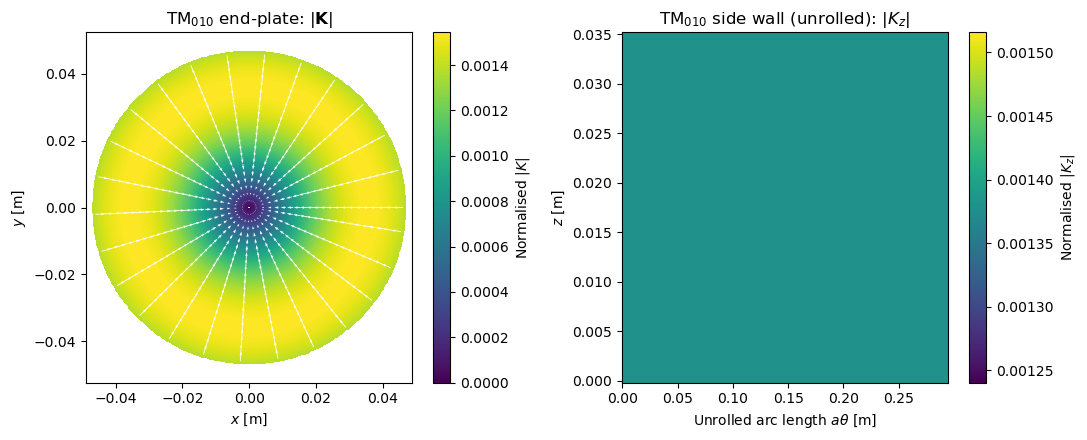

In [72]:
# ============================================================
# TM010 SURFACE CURRENT DENSITY
# ============================================================
#
# Side wall (r = a), n_hat = r_hat:
#   K_side = r_hat x (Hr r_hat + Hth th_hat) = Hth z_hat
#
# End plate (z = c), n_hat = z_hat:
#   K_end  = z_hat x (Hr r_hat + Hth th_hat) = Hr th_hat - Hth r_hat
#
# For TM010, Hr = 0 everywhere, so the end-plate current is purely
# radial and the side-wall current is purely axial.
# ============================================================

K_side_010 = Hth_010.subs(r, a)      # coefficient of z_hat, at r = a
K_end_010 = -Hth_010                 # coefficient of r_hat (Hr_010 = 0)

display(Markdown("### TM$_{010}$ surface current density"))

show_equation(sp.Eq(sp.Symbol(r'\mathbf{K}_{side,010}\cdot\hat{z}'), K_side_010))
show_equation(sp.Eq(sp.Symbol(r'\mathbf{K}_{end,010}\cdot\hat{r}'), K_end_010))

# Numeric field arrays (reuse R, THETA from the TM010 field-plot cell above)
Hth010_current = (omega010_num * eps_num / k010_num) * jv(1, k010_num * R)

Kx_end010 = -Hth010_current * np.cos(THETA)
Ky_end010 = -Hth010_current * np.sin(THETA)
Kmag_end010 = np.abs(Hth010_current)

theta_line = np.linspace(0, 2*np.pi, 300)
z_line = np.linspace(0, c_cyl, 100)
TH_wall, Z_wall = np.meshgrid(theta_line, z_line)
Kz_side010 = (omega010_num * eps_num / k010_num) * jv(1, k010_num * a_cyl) * np.ones_like(TH_wall)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))

X_end = R * np.cos(THETA)
Y_end = R * np.sin(THETA)
pc = axs[0].pcolormesh(X_end, Y_end, Kmag_end010, shading='auto', cmap='viridis')
step = 14
axs[0].quiver(
    X_end[::step, ::step], Y_end[::step, ::step],
    Kx_end010[::step, ::step], Ky_end010[::step, ::step],
    color='white'
)
axs[0].set_xlabel('$x$ [m]')
axs[0].set_ylabel('$y$ [m]')
axs[0].set_title(r'TM$_{010}$ end-plate: $|\mathbf{K}|$')
axs[0].axis('equal')
plt.colorbar(pc, ax=axs[0], label='Normalised $|K|$')

pc2 = axs[1].pcolormesh(a_cyl*TH_wall, Z_wall, np.abs(Kz_side010), shading='auto', cmap='viridis')
axs[1].set_xlabel(r'Unrolled arc length $a\theta$ [m]')
axs[1].set_ylabel('$z$ [m]')
axs[1].set_title(r'TM$_{010}$ side wall (unrolled): $|K_z|$')
plt.colorbar(pc2, ax=axs[1], label='Normalised $|K_z|$')

plt.tight_layout()
plt.show()


### TM$_{110}$ surface current density

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

C:\Users\RafIc\AppData\Local\Temp\ipykernel_8932\461150349.py:24: RuntimeWarning: invalid value encountered in divide
  (omega110_num * eps_num / k110_num**2) * jv(1, k110_num * R) / R * np.sin(THETA)
C:\Users\RafIc\AppData\Local\Temp\ipykernel_8932\461150349.py:46: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = axs[0].pcolormesh(X_end, Y_end, Kmag_end110, shading='auto', cmap='viridis')


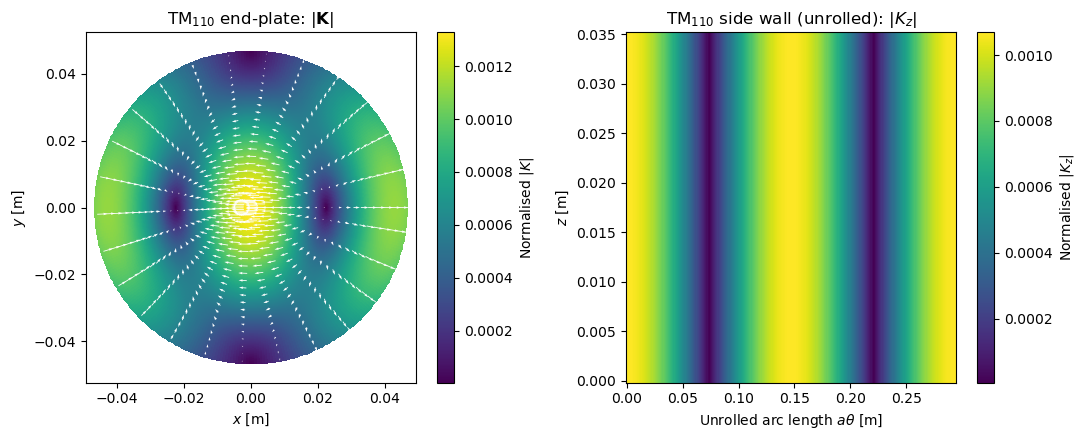

In [73]:
# ============================================================
# TM110 SURFACE CURRENT DENSITY
# ============================================================
#
# Side wall (r = a), n_hat = r_hat:
#   K_side = Hth z_hat   (Hr = 0 at r = a, by the J1(k110 a) = 0
#   boundary condition, so only Htheta contributes)
#
# End plate (z = c), n_hat = z_hat:
#   K_end = Hr th_hat - Hth r_hat
# ============================================================

K_side_110 = sp.simplify(Hth_110.subs(r, a))
K_end_110 = sp.Matrix([Hr_110, -Hth_110])  # [theta_hat, r_hat] components

display(Markdown("### TM$_{110}$ surface current density"))

show_equation(sp.Eq(sp.Symbol(r'\mathbf{K}_{side,110}\cdot\hat{z}'), K_side_110))
show_equation(sp.Eq(sp.Symbol(r'\mathbf{K}_{end,110}\cdot\hat{\theta}'), Hr_110))
show_equation(sp.Eq(sp.Symbol(r'\mathbf{K}_{end,110}\cdot\hat{r}'), -Hth_110))

# Numeric field arrays (reuse R, THETA from the TM110 field-plot cell above)
Hr110_current = (
    (omega110_num * eps_num / k110_num**2) * jv(1, k110_num * R) / R * np.sin(THETA)
)
Hth110_current = (
    (omega110_num * eps_num / k110_num) * jvp(1, k110_num * R) * np.cos(THETA)
)

Kr_end110 = -Hth110_current
Kth_end110 = Hr110_current
Kx_end110 = Kr_end110*np.cos(THETA) - Kth_end110*np.sin(THETA)
Ky_end110 = Kr_end110*np.sin(THETA) + Kth_end110*np.cos(THETA)
Kmag_end110 = np.sqrt(Hr110_current**2 + Hth110_current**2)

theta_line = np.linspace(0, 2*np.pi, 300)
z_line = np.linspace(0, c_cyl, 100)
TH_wall, Z_wall = np.meshgrid(theta_line, z_line)
Hth110_wall = (omega110_num * eps_num / k110_num) * jvp(1, k110_num * a_cyl) * np.cos(theta_line)
Kz_side110 = np.tile(Hth110_wall, (len(z_line), 1))

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))

X_end = R * np.cos(THETA)
Y_end = R * np.sin(THETA)
pc = axs[0].pcolormesh(X_end, Y_end, Kmag_end110, shading='auto', cmap='viridis')
step = 14
axs[0].quiver(
    X_end[::step, ::step], Y_end[::step, ::step],
    Kx_end110[::step, ::step], Ky_end110[::step, ::step],
    color='white'
)
axs[0].set_xlabel('$x$ [m]')
axs[0].set_ylabel('$y$ [m]')
axs[0].set_title(r'TM$_{110}$ end-plate: $|\mathbf{K}|$')
axs[0].axis('equal')
plt.colorbar(pc, ax=axs[0], label='Normalised $|K|$')

pc2 = axs[1].pcolormesh(a_cyl*TH_wall, Z_wall, np.abs(Kz_side110), shading='auto', cmap='viridis')
axs[1].set_xlabel(r'Unrolled arc length $a\theta$ [m]')
axs[1].set_ylabel('$z$ [m]')
axs[1].set_title(r'TM$_{110}$ side wall (unrolled): $|K_z|$')
plt.colorbar(pc2, ax=axs[1], label='Normalised $|K_z|$')

plt.tight_layout()
plt.show()


### TM$_{210}$ surface current density

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

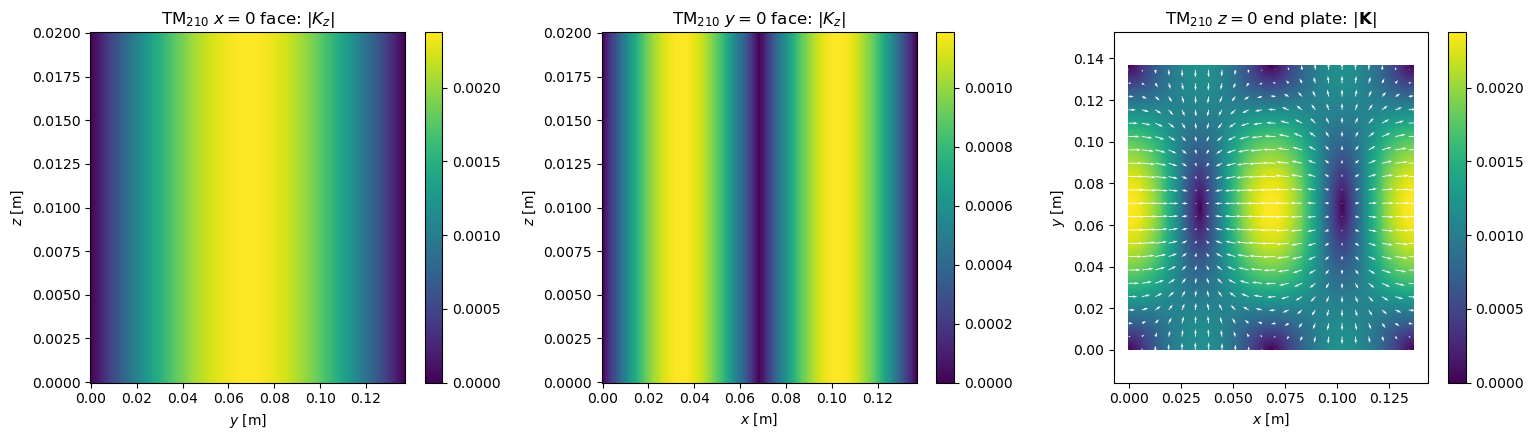

In [74]:
# ============================================================
# TM210 SURFACE CURRENT DENSITY
# ============================================================
#
# x = 0 / x = a faces, n_hat = +-x_hat:  K = Hy z_hat
# y = 0 / y = a faces, n_hat = +-y_hat:  K = -Hx z_hat
# z = 0 / z = c faces, n_hat = +-z_hat:  K = Hx y_hat - Hy x_hat
#
# Because the cavity is square, the x=0/x=a pair, the y=0/y=a pair,
# and the z=0/z=c pair each carry the same current pattern (up to a
# sign), so only one representative face from each pair is plotted.
# ============================================================

K_xface_210 = Hy_210.subs(x, 0)
K_yface_210 = -Hx_210.subs(y, 0)
K_zface_210 = sp.Matrix([Hx_210, -Hy_210])   # [y_hat, x_hat] components

display(Markdown("### TM$_{210}$ surface current density"))

show_equation(sp.Eq(sp.Symbol(r'\mathbf{K}_{x=0}\cdot\hat{z}'), K_xface_210))
show_equation(sp.Eq(sp.Symbol(r'\mathbf{K}_{y=0}\cdot\hat{z}'), K_yface_210))
show_equation(sp.Eq(sp.Symbol(r'\mathbf{K}_{z=0}\cdot\hat{y}'), Hx_210))
show_equation(sp.Eq(sp.Symbol(r'\mathbf{K}_{z=0}\cdot\hat{x}'), -Hy_210))

# Numeric field arrays (reuse X, Y from the TM210 field-plot cell above)
def Hx210_current(xv, yv):
    return (
        (omega210_num * eps_num * a_sq / (5*np.pi))
        * np.sin(2*np.pi*xv/a_sq) * np.cos(np.pi*yv/a_sq)
    )

def Hy210_current(xv, yv):
    return (
        -(2*omega210_num * eps_num * a_sq / (5*np.pi))
        * np.cos(2*np.pi*xv/a_sq) * np.sin(np.pi*yv/a_sq)
    )

z_array = np.linspace(0, c_sq, N)

Y_xface, Z_xface = np.meshgrid(y_array, z_array)
Kz_xface = np.abs(Hy210_current(np.zeros_like(Y_xface), Y_xface))

X_yface, Z_yface = np.meshgrid(x_array, z_array)
Kz_yface = np.abs(Hx210_current(X_yface, np.zeros_like(X_yface)))

Kx_zface = -Hy210_current(X, Y)
Ky_zface = Hx210_current(X, Y)
Kmag_zface = np.sqrt(Kx_zface**2 + Ky_zface**2)

fig, axs = plt.subplots(1, 3, figsize=(15.5, 4.5))

pc0 = axs[0].pcolormesh(Y_xface, Z_xface, Kz_xface, shading='auto', cmap='viridis')
axs[0].set_xlabel('$y$ [m]')
axs[0].set_ylabel('$z$ [m]')
axs[0].set_title(r'TM$_{210}$ $x=0$ face: $|K_z|$')
plt.colorbar(pc0, ax=axs[0])

pc1 = axs[1].pcolormesh(X_yface, Z_yface, Kz_yface, shading='auto', cmap='viridis')
axs[1].set_xlabel('$x$ [m]')
axs[1].set_ylabel('$z$ [m]')
axs[1].set_title(r'TM$_{210}$ $y=0$ face: $|K_z|$')
plt.colorbar(pc1, ax=axs[1])

pc2 = axs[2].pcolormesh(X, Y, Kmag_zface, shading='auto', cmap='viridis')
step = 14
axs[2].quiver(
    X[::step, ::step], Y[::step, ::step],
    Kx_zface[::step, ::step], Ky_zface[::step, ::step],
    color='white'
)
axs[2].set_xlabel('$x$ [m]')
axs[2].set_ylabel('$y$ [m]')
axs[2].set_title(r'TM$_{210}$ $z=0$ end plate: $|\mathbf{K}|$')
axs[2].axis('equal')
plt.colorbar(pc2, ax=axs[2])

plt.tight_layout()
plt.show()


# Equivalent Circuit Model (Parallel RLC)

Near its resonant frequency, a single cavity mode responds exactly
like a **current-driven parallel $R\parallel L\parallel C$ resonator**:

\[
Y(\omega) = \frac{1}{R} + j\omega C + \frac{1}{j\omega L}.
\]

Two properties of this circuit are fixed unambiguously by the cavity
physics already derived above:

\[
\omega_0 = \frac{1}{\sqrt{LC}}, \qquad
Q_0 = \omega_0 R C = \frac{R}{\omega_0 L}.
\]

These two equations relate three unknowns ($L$, $C$, $R$), so one
more piece of information is needed to pin down their *absolute*
values. Physically, that missing piece is the **coupling** between
the external current source and the cavity mode (e.g. a loop or probe
geometry) — which we are explicitly told to ignore here. Without a
coupling design there is no unique "impedance level" for the circuit:
only the combinations $\omega_0$ and $Q_0$ are intrinsic to the
cavity mode itself.

To make the circuit concrete, we introduce the resonator's
**characteristic impedance** $Z_0=\sqrt{L/C}$ as a free/symbolic
parameter (this is exactly the quantity a coupling design would fix).
In terms of $Z_0$:

\[
L = \frac{Z_0}{\omega_0}, \qquad
C = \frac{1}{\omega_0 Z_0}, \qquad
R = Q_0 Z_0.
\]

This reproduces $\omega_0=1/\sqrt{LC}$ and $Q_0=\omega_0 RC$
identically for *any* $Z_0>0$ — the self-check below confirms this
symbolically. For illustration only, the numerical example uses
$Z_0=50\,\Omega$ (a conventional RF reference impedance); replace it
with whatever value a real coupling structure would present once one
is designed.


In [75]:
# ============================================================
# EQUIVALENT PARALLEL R-L-C CIRCUIT (per mode)
# ============================================================
#
# omega0 = 1/sqrt(LC)
# Q0     = omega0 * R * C = R / (omega0 * L)
#
# Z0 = sqrt(L/C) is left as a free (coupling-dependent) parameter,
# and Q_XXX_final (derived earlier) is already expressed using the
# generic 'omega' symbol evaluated at resonance, i.e. omega == omega0:
#
#   L = Z0/omega,  C = 1/(omega*Z0),  R = Q0*Z0
# ============================================================

Z0 = sp.Symbol('Z_0', positive=True, real=True)


def equivalent_rlc(Q0_expr):
    L_expr = Z0 / omega
    C_expr = 1 / (omega * Z0)
    R_expr = Q0_expr * Z0
    return L_expr, C_expr, R_expr


L_010, C_010, R_010 = equivalent_rlc(Q_010_final)
L_110, C_110, R_110 = equivalent_rlc(Q_110_final)
L_210, C_210, R_210 = equivalent_rlc(Q_210_final)

display(Markdown("### TM$_{010}$ equivalent circuit"))
show_equation(sp.Eq(sp.Symbol('L_{010}'), sp.simplify(L_010)))
show_equation(sp.Eq(sp.Symbol('C_{010}'), sp.simplify(C_010)))
show_equation(sp.Eq(sp.Symbol('R_{010}'), sp.simplify(R_010)))

display(Markdown("### TM$_{110}$ equivalent circuit"))
show_equation(sp.Eq(sp.Symbol('L_{110}'), sp.simplify(L_110)))
show_equation(sp.Eq(sp.Symbol('C_{110}'), sp.simplify(C_110)))
show_equation(sp.Eq(sp.Symbol('R_{110}'), sp.simplify(R_110)))

display(Markdown("### TM$_{210}$ equivalent circuit"))
show_equation(sp.Eq(sp.Symbol('L_{210}'), sp.simplify(L_210)))
show_equation(sp.Eq(sp.Symbol('C_{210}'), sp.simplify(C_210)))
show_equation(sp.Eq(sp.Symbol('R_{210}'), sp.simplify(R_210)))

# Self-check: these L, C, R reproduce omega0 = 1/sqrt(LC) and
# Q0 = omega0*R*C exactly, for every mode and for any Z0 > 0.
for L_e, C_e, R_e, Q0_e, label in [
    (L_010, C_010, R_010, Q_010_final, "TM010"),
    (L_110, C_110, R_110, Q_110_final, "TM110"),
    (L_210, C_210, R_210, Q_210_final, "TM210"),
]:
    assert sp.simplify(1/sp.sqrt(L_e*C_e) - omega) == 0, f"{label}: omega0 != 1/sqrt(LC)"
    assert sp.simplify(omega*R_e*C_e - Q0_e) == 0, f"{label}: Q0 != omega0*R*C"

print("Self-check passed: omega0 = 1/sqrt(LC) and Q0 = omega0*R*C hold for all three modes.")

# ------------------------------------------------------------
# Numerical illustration with an assumed Z0 = 50 ohm reference
# impedance (a placeholder until a real coupling structure is
# designed -- see the discussion above).
# ------------------------------------------------------------

Z0_num = 50.0  # ohm, arbitrary placeholder

for omega_num, Q_num, label in [
    (omega010_num, Q010_num, "TM010"),
    (omega110_num, Q110_num, "TM110"),
    (omega210_num, Q210_num, "TM210"),
]:
    L_num = Z0_num / omega_num
    C_num = 1 / (omega_num * Z0_num)
    R_num = Q_num * Z0_num
    print(
        f"{label}: L = {L_num*1e9:.4f} nH,  "
        f"C = {C_num*1e12:.4f} pF,  "
        f"R = {R_num/1e3:.4f} kohm   (Z0 = {Z0_num:.0f} ohm)"
    )


### TM$_{010}$ equivalent circuit

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### TM$_{110}$ equivalent circuit

...

### TM$_{210}$ equivalent circuit

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Self-check passed: omega0 = 1/sqrt(LC) and Q0 = omega0*R*C hold for all three modes.
TM010: L = 3.2480 nH,  C = 1.2992 pF,  R = 582.7266 kohm   (Z0 = 50 ohm)
TM110: L = 2.0385 nH,  C = 0.8154 pF,  R = 928.4819 kohm   (Z0 = 50 ohm)
TM210: L = 3.2481 nH,  C = 1.2992 pF,  R = 450.2017 kohm   (Z0 = 50 ohm)


## Predictions for Effect of Samples in Cavities

## Exact perturbation numerators

Every coefficient used in the prediction model is derived below rather than
quoted. The starting point is the Bethe–Schwinger material perturbation
theorem, which for an air-filled unperturbed cavity reads

$$\frac{\delta\omega}{\omega_0} \;=\; -\,\frac{\displaystyle\int_{\Delta V}\big(\Delta\varepsilon\,\mathbf E_{\rm in}\!\cdot\!\mathbf E_0^{*} \;+\; \Delta\mu\,\mathbf H_{\rm in}\!\cdot\!\mathbf H_0^{*}\big)\,dV}{4\,(W_e+W_m)}$$

Two things deserve emphasis, because they are the only places where anything
other than direct integration enters.

**1. The internal field is not the unperturbed field.** The integrand contains
$\mathbf E_{\rm in}$, the *total* field inside the sample. For an ellipsoid in
a uniform applied field the internal field is uniform and related to the
applied field by the depolarising/demagnetising factor $N$:

$$\mathbf E_{\rm in} \;=\; \frac{\mathbf E_0}{1+N(\varepsilon_r-1)}
\qquad\Longrightarrow\qquad
\Delta\varepsilon\,\mathbf E_{\rm in}\!\cdot\!\mathbf E_0^{*}
\;=\; \varepsilon\,\frac{\varepsilon_r-1}{1+N(\varepsilon_r-1)}\,|\mathbf E_0|^2$$

The factor $(\varepsilon_r-1)$ is the material *contrast*, coming from
$\Delta\varepsilon=\varepsilon(\varepsilon_r-1)$; the denominator
$1+N(\varepsilon_r-1)$ is the *field reduction* inside the sample. They are
separate effects that multiply. $N$ is carried symbolically throughout and is
only given a value at the very end.

**2. No thin-rod assumption is made in this section.** The volume integrals
below are evaluated exactly over the full 10 mm rod. The thin-rod limit — the
step that turns $\int_{\Delta V}|\mathbf E_0|^2dV$ into $|\mathbf E_0|^2 V_1$
and hence produces the familiar $V_1/V_0$ textbook forms — is deferred to its
own section at the end, so that its size can be measured rather than assumed.

The denominators are taken from the stored-energy results derived earlier in
this notebook ($W_e=W_m$ at resonance, so $4(W_e+W_m)=8W_e$). Those already
incorporate the cavity boundary conditions ($J_0(k_{010}a)=0$ and
$J_1(k_{110}a)=0$ respectively); **no boundary condition is needed in the
numerators**, because the sample integrals run over the rod, not the cavity.


In [76]:
# ============================================================
# EXACT NUMERATOR -- TM010, dielectric rod on the axis
# ============================================================

r_s = sp.Symbol('r_s', positive=True)          # rod radius
eps_r = sp.Symbol('varepsilon_r', positive=True)
mu_eff = sp.Symbol('mu_eff', positive=True)
N_dep = sp.Symbol('N', nonnegative=True)
rho, varphi = sp.symbols('rho varphi', positive=True)


def show_named(lhs_latex, expr):
    """Display 'lhs = expr', with the left-hand side given as raw LaTeX.

    sympy's Symbol printer garbles names containing both '_' and '^',
    so labels such as |E_0|^2 are written out directly instead.
    """
    display(Math(lhs_latex + " = " + sp.latex(expr)))


display(Markdown("### TM$_{010}$ — step 1: the unperturbed field, from the notebook's own definition"))
show_equation(sp.Eq(sp.Symbol('E_{z,010}'), Ez_010))

display(Markdown(r"Step 2: $|E_0|^2$ integrated over the rod ($0\le r\le r_s$, full height $c$, all $\theta$)."))

E2_010 = sp.simplify(Ez_010*sp.conjugate(Ez_010))
show_named(r'\left|\mathbf{E}_0\right|^2', E2_010)

radial_010 = sp.simplify(sp.integrate(E2_010*r, (r, 0, r_s)))
show_named(r'\int_0^{r_s}\left|\mathbf{E}_0\right|^2 r\,dr', radial_010)

IntE2_010 = sp.simplify(2*pi*c*radial_010)
show_named(r'\int_{\Delta V}\left|\mathbf{E}_0\right|^2 dV', IntE2_010)

display(Markdown(
    r"Step 3: multiply by the contrast/field-reduction factor. The rod axis is "
    r"**parallel** to $E_z$, but $N$ is kept symbolic for now."
))

contrast_E = (eps_r - 1)/(1 + N_dep*(eps_r - 1))
Num_010 = sp.simplify(eps*contrast_E*IntE2_010)
show_equation(sp.Eq(sp.Symbol(r'\mathrm{Num}_{010}'), Num_010))

display(Markdown(r"Step 4: the denominator $4(W_e+W_m)=8W_e$, from the stored energy derived earlier."))

Den_010 = sp.simplify(8*We_010_closed)
show_equation(sp.Eq(sp.Symbol('4(W_e+W_m)_{010}'), Den_010))

display(Markdown(r"Step 5: the **exact** fractional frequency shift, no approximation of any kind."))

S_010_exact = sp.simplify(-Num_010/Den_010)
show_named(r'\left.\delta\omega/\omega\right|_{010}^{\mathrm{exact}}', S_010_exact)


### TM$_{010}$ — step 1: the unperturbed field, from the notebook's own definition

<IPython.core.display.Math object>

Step 2: $|E_0|^2$ integrated over the rod ($0\le r\le r_s$, full height $c$, all $\theta$).

<IPython.core.display.Math object>

<IPython.core.display.Math object>

...

<IPython.core.display.Math object>

Step 4: the denominator $4(W_e+W_m)=8W_e$, from the stored energy derived earlier.

<IPython.core.display.Math object>

Step 5: the **exact** fractional frequency shift, no approximation of any kind.

<IPython.core.display.Math object>

In [77]:
# ============================================================
# EXACT NUMERATOR -- TM110, gyromagnetic rod on the axis
# ============================================================
#
# On the axis Ez = A J1(k r) cos(theta) vanishes, so the sample
# sees a purely magnetic perturbation.
# ============================================================

display(Markdown("### TM$_{110}$ — step 1: the unperturbed fields, from the notebook's own definitions"))
show_equation(sp.Eq(sp.Symbol('H_{r,110}'), Hr_110))
show_equation(sp.Eq(sp.Symbol(r'H_{\theta,110}'), sp.simplify(Hth_110)))

display(Markdown(
    r"Note that `sp.diff(besselj(1, k r), r)` differentiates with respect to $r$, "
    r"so it already carries the chain-rule factor $k$, i.e. it equals $k\,J_1'(kr)$."
))

display(Markdown(r"Step 2: form $|H_0|^2=|H_r|^2+|H_\theta|^2$ directly from those fields."))

H2_110 = sp.simplify(sp.expand_complex(
    Hr_110*sp.conjugate(Hr_110) + Hth_110*sp.conjugate(Hth_110)))
show_named(r'\left|\mathbf{H}_0\right|^2', H2_110)

display(Markdown(r"Step 3: integrate over $\theta$ (this is where $\sin^2$/$\cos^2$ each give $\pi$)."))

ang_110 = sp.simplify(sp.integrate(H2_110*r, (theta, 0, 2*pi)))
show_named(r'\oint \left|\mathbf{H}_0\right|^2 r\,d\theta', ang_110)

display(Markdown(
    r"Step 4: integrate over $r$ from $0$ to $r_s$. SymPy evaluates this in closed "
    r"form, including the $\int J_1^2/r\,dr$ term."
))

radial_110 = sp.simplify(sp.integrate(sp.expand(ang_110), (r, 0, r_s)))
IntH2_110 = sp.simplify(c*radial_110)
show_named(r'\int_{\Delta V}\left|\mathbf{H}_0\right|^2 dV', IntH2_110)

display(Markdown(
    r"Step 5: apply the contrast/field-reduction factor and divide by "
    r"$4(W_e+W_m)=8W_e$, then eliminate $\mu$ using the resonance relation "
    r"$\mu\,\omega^2\varepsilon=k_{110}^2$."
))

contrast_H = (mu_eff - 1)/(1 + N_dep*(mu_eff - 1))
Num_110 = sp.simplify(mu*contrast_H*IntH2_110)
Den_110 = sp.simplify(8*We_110_closed)
show_equation(sp.Eq(sp.Symbol(r'\mathrm{Num}_{110}'), Num_110))
show_equation(sp.Eq(sp.Symbol('4(W_e+W_m)_{110}'), Den_110))

S_110_exact = sp.simplify(-Num_110/Den_110)
S_110_exact = sp.simplify(S_110_exact.subs(mu, k_110**2/(omega**2*eps)))
show_named(r'\left.\delta\omega/\omega\right|_{110}^{\mathrm{exact}}', S_110_exact)


### TM$_{110}$ — step 1: the unperturbed fields, from the notebook's own definitions

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Note that `sp.diff(besselj(1, k r), r)` differentiates with respect to $r$, so it already carries the chain-rule factor $k$, i.e. it equals $k\,J_1'(kr)$.

Step 2: form $|H_0|^2=|H_r|^2+|H_\theta|^2$ directly from those fields.

...

<IPython.core.display.Math object>

Step 5: apply the contrast/field-reduction factor and divide by $4(W_e+W_m)=8W_e$, then eliminate $\mu$ using the resonance relation $\mu\,\omega^2\varepsilon=k_{110}^2$.

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [78]:
# ============================================================
# EXACT NUMERATOR -- TM210, gyromagnetic rod at the cavity centre
# ============================================================
#
# At (a/2, a/2) both TM210 and its degenerate partner TM120 have
# Ez = 0, so again the perturbation is purely magnetic.
# ============================================================

from sympy.simplify.fu import TR7, TR8

display(Markdown("### TM$_{210}$ — step 1: the unperturbed fields, from the notebook's own definitions"))
show_equation(sp.Eq(sp.Symbol('H_{x,210}'), Hx_210))
show_equation(sp.Eq(sp.Symbol('H_{y,210}'), Hy_210))

H2_210 = sp.simplify(sp.expand_complex(Hx_210*sp.conjugate(Hx_210))
                     + sp.expand_complex(Hy_210*sp.conjugate(Hy_210)))
show_named(r'\left|\mathbf{H}_0\right|^2', H2_210)

display(Markdown(
    r"Step 2: shift to polar coordinates $(\rho,\varphi)$ centred on the rod at "
    r"$(a/2,\,a/2)$, then use the half-angle and product-to-sum identities "
    r"(SymPy's `TR7`/`TR8`) so that every term becomes a single cosine."
))

H2_shift = sp.simplify(H2_210.subs({x: a/2 + rho*sp.cos(varphi),
                                    y: a/2 + rho*sp.sin(varphi)}))
H2_red = sp.expand(TR8(TR7(H2_shift)))
show_named(r'\left|\mathbf{H}_0\right|^2(\rho,\varphi)', H2_red)

display(Markdown(
    r"""Step 3: the angular integral. SymPy cannot evaluate
$\int_0^{2\pi}\cos(\alpha\cos\varphi+\beta\sin\varphi)\,d\varphi$ directly, so the
standard Bessel integral representation is supplied **explicitly** here:

$$\int_0^{2\pi}\cos\!\big(\alpha\cos\varphi+\beta\sin\varphi\big)\,d\varphi
\;=\; 2\pi\,J_0\!\left(\sqrt{\alpha^2+\beta^2}\right)$$

It is verified below by series expansion before being used."""
))

_z = sp.Symbol('z', positive=True)
_lhs = sp.integrate(sp.series(sp.cos(_z*sp.cos(varphi)), _z, 0, 9).removeO(), (varphi, 0, 2*pi))
_rhs = sp.series(2*pi*sp.besselj(0, _z), _z, 0, 9).removeO()
assert sp.simplify(sp.expand(_lhs - _rhs)) == 0, "Bessel angular identity failed verification"
print("Verified to O(z^8):  int_0^2pi cos(z cos(phi)) dphi = 2 pi J0(z)")


def angular_integral(expr):
    """Integrate a sum of cosines over varphi in [0, 2*pi] using the identity above."""
    total = 0
    for term in sp.Add.make_args(sp.expand(expr)):
        coeff, rest = term.as_independent(varphi)
        if rest == 1:
            total += coeff*2*pi
            continue
        assert isinstance(rest, sp.cos), f"unexpected angular factor: {rest}"
        arg = sp.expand(rest.args[0])
        alpha = arg.coeff(sp.cos(varphi))
        beta = arg.coeff(sp.sin(varphi))
        assert sp.simplify(arg - alpha*sp.cos(varphi) - beta*sp.sin(varphi)) == 0, \
            "angular argument is not of the form alpha*cos + beta*sin"
        total += coeff*2*pi*sp.besselj(0, sp.sqrt(sp.simplify(alpha**2 + beta**2)))
    return sp.simplify(total)


ang_210 = angular_integral(H2_red)
show_named(r'\oint \left|\mathbf{H}_0\right|^2 d\varphi', ang_210)

display(Markdown(r"Step 4: integrate $\rho$ from $0$ to $r_s$ over the rod cross-section."))

IntH2_210 = sp.simplify(c*sp.integrate(sp.expand(ang_210*rho), (rho, 0, r_s)))
show_named(r'\int_{\Delta V}\left|\mathbf{H}_0\right|^2 dV', IntH2_210)

display(Markdown(
    r"Step 5: contrast/field-reduction factor, divide by $4(W_e+W_m)=8W_e$, and "
    r"eliminate $\mu$ via $\mu\,\omega^2\varepsilon=k_{210}^2=5\pi^2/a^2$."
))

Num_210 = sp.simplify(mu*contrast_H*IntH2_210)
Den_210 = sp.simplify(8*We_210)
show_equation(sp.Eq(sp.Symbol(r'\mathrm{Num}_{210}'), Num_210))
show_equation(sp.Eq(sp.Symbol('4(W_e+W_m)_{210}'), Den_210))

S_210_exact = sp.simplify(-Num_210/Den_210)
S_210_exact = sp.simplify(S_210_exact.subs(mu, k_210**2/(omega**2*eps)))
show_named(r'\left.\delta\omega/\omega\right|_{210}^{\mathrm{exact}}', S_210_exact)


### TM$_{210}$ — step 1: the unperturbed fields, from the notebook's own definitions

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Step 2: shift to polar coordinates $(\rho,\varphi)$ centred on the rod at $(a/2,\,a/2)$, then use the half-angle and product-to-sum identities (SymPy's `TR7`/`TR8`) so that every term becomes a single cosine.

...

<IPython.core.display.Math object>

Step 5: contrast/field-reduction factor, divide by $4(W_e+W_m)=8W_e$, and eliminate $\mu$ via $\mu\,\omega^2\varepsilon=k_{210}^2=5\pi^2/a^2$.

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Thin-rod limit

The three results above are exact for a rod of any radius $r_s$. The familiar
textbook forms, in which the sample enters only through the filling factor

$$\eta \;\equiv\; \frac{V_1}{V_0}$$

follow from a single further step: assuming the unperturbed field is uniform
across the sample, so that

$$\int_{\Delta V}|\mathbf F_0|^2\,dV \;\longrightarrow\; |\mathbf F_0|^2\,V_1$$

This is the standard "sufficiently small sample" assumption.

Taking it explicitly here lets its size be measured. Expanding each exact shift
in powers of the rod radius,

$$S_{\rm exact}(r_s) \;=\; c_2 r_s^2 + c_4 r_s^4 + \dots$$

the thin-rod result is the leading term $S_{\rm thin}=c_2r_s^2$, and the
**form factor**

$$F(r_s) \;=\; \frac{S_{\rm exact}}{S_{\rm thin}} \;=\; 1 + \frac{c_4}{c_2}r_s^2+\dots$$

measures the error incurred. For a full-height rod the cavity height cancels, so
$\eta=r_s^2/a^2$ for the cylindrical cavities and $\eta=\pi r_s^2/a^2$ for the
square one.

The depolarising factor $N$ is also given its geometric value at this point:
$N=0$ for TM$_{010}$ (rod parallel to $E_z$, so tangential-$E$ continuity means
the field inside it is unchanged and no correction arises) and $N=1/2$ for
TM$_{110}$/TM$_{210}$ (rod transverse to $\mathbf H$).


In [79]:
# ============================================================
# THIN-ROD LIMIT AND FORM FACTORS
# ============================================================
#
# Each exact shift is expanded in powers of the rod radius,
#
#     S_exact(r_s)  =  c2*r_s^2 + c4*r_s^4 + ...
#
# The thin-rod (textbook) result is the leading term, and the
# form factor measuring the size of that assumption is
#
#     F(r_s)  =  S_exact / S_thin  =  1 + (c4/c2)*r_s^2 + ...
#
# The depolarising factor N is given its geometric value here for
# the first time:
#     N = 0    TM010        (rod parallel to Ez; tangential E is
#                            continuous, so the field inside is
#                            unchanged and no correction arises)
#     N = 1/2  TM110/TM210  (rod transverse to H)
#
# SymPy cannot series-expand a squared Bessel function directly, so
# each r_s-dependent besselj is replaced by its own sympy-generated
# Taylor series first and the result is then expanded. The series
# are produced by sympy, not entered by hand.
# ============================================================

VR = sp.Symbol('eta', positive=True)      # filling factor V1/V0


def bessel_series(expr, var, order):
    """Replace every var-dependent besselj by its sympy-generated Taylor series."""
    reps = {b: sp.series(b, var, 0, order).removeO()
            for b in expr.atoms(sp.besselj) if b.has(var)}
    return sp.expand(expr.subs(reps))


def rs_coeffs(S_exact, order=6):
    """Coefficients of r_s**n in the Bessel-expanded shift."""
    poly = sp.Poly(bessel_series(S_exact, r_s, order), r_s)
    return {n: sp.simplify(poly.coeff_monomial(r_s**n) if n else poly.coeff_monomial(1))
            for n in range(0, 7)}


def thin_and_form(S_exact, label):
    """Split an exact shift into its thin-rod term and its form factor."""
    cf = rs_coeffs(S_exact)
    assert cf[0] == 0 and cf[1] == 0 and cf[3] == 0, \
        f"{label}: shift should contain only even powers of r_s starting at r_s^2"
    S_thin = sp.simplify(cf[2]*r_s**2)
    F = sp.simplify(1 + sp.simplify(cf[4]/cf[2])*r_s**2)
    return S_thin, F


display(Markdown("### Thin-rod shifts"))

S_010_N = sp.simplify(S_010_exact.subs(N_dep, 0))                    # N = 0
S_110_N = sp.simplify(S_110_exact.subs(N_dep, sp.Rational(1, 2)))    # N = 1/2
S_210_N = sp.simplify(S_210_exact.subs(N_dep, sp.Rational(1, 2)))    # N = 1/2

S_010_thin, F_010 = thin_and_form(S_010_N, "TM010")
S_110_thin, F_110 = thin_and_form(S_110_N, "TM110")
S_210_thin, F_210 = thin_and_form(S_210_N, "TM210")

# V1/V0 = r_s^2/a^2 (cylindrical), pi*r_s^2/a^2 (square)
S_010_thin_VR = sp.simplify(S_010_thin.subs(r_s**2, VR*a**2))
S_110_thin_VR = sp.simplify(S_110_thin.subs(r_s**2, VR*a**2))
S_210_thin_VR = sp.simplify(S_210_thin.subs(r_s**2, VR*a**2/pi))

show_named(r'\left.\delta\omega/\omega\right|_{010}', S_010_thin_VR)
show_named(r'\left.\delta\omega/\omega\right|_{110}', S_110_thin_VR)
show_named(r'\left.\delta\omega/\omega\right|_{210}', S_210_thin_VR)

display(Markdown("### Form factors, i.e. the size of the thin-rod assumption"))

show_equation(sp.Eq(sp.Symbol('F_{010}'), F_010))
show_equation(sp.Eq(sp.Symbol('F_{110}'), F_110))
show_equation(sp.Eq(sp.Symbol('F_{210}'), F_210))

display(Markdown(
    r"All three reduce to the same leading behaviour $F\simeq1-(kr_s)^2/4$ "
    r"(for TM$_{210}$, recall $k_{210}^2=5\pi^2/a^2$). Since all three cavities "
    r"resonate at the same frequency they share the same $k$, which is why the "
    r"numerical corrections below come out near-identical."
))

# ------------------------------------------------------------
# Coefficients entering the prediction model
# ------------------------------------------------------------

coeff_010_sym = sp.simplify(-S_010_thin_VR/(VR*(eps_r - 1)))
coeff_110_sym = sp.simplify(-S_110_thin_VR/(VR*(mu_eff - 1)/(mu_eff + 1)))
coeff_210_sym = sp.simplify(-S_210_thin_VR/(VR*(mu_eff - 1)/(mu_eff + 1)))

display(Markdown("### Coefficients entering the prediction model"))
show_equation(sp.Eq(sp.Symbol('C_{010}'), coeff_010_sym))
show_equation(sp.Eq(sp.Symbol('C_{110}'), coeff_110_sym))
show_equation(sp.Eq(sp.Symbol('C_{210}'), coeff_210_sym))

coeff_010 = float(coeff_010_sym.subs(sp.besselj(1, k_010*a), sp.besselj(1, sp.Float(x01))).evalf())
coeff_110 = float(coeff_110_sym.subs(sp.besselj(0, k_110*a), sp.besselj(0, sp.Float(x11))).evalf())
coeff_210 = float(coeff_210_sym)

print(f"C_010 = {coeff_010:.6f}   = 1/(2 J1(x01)^2)")
print(f"C_110 = {coeff_110:.6f}   = 1/(2 J0(x11)^2)")
print(f"C_210 = {coeff_210:.6f}   = 16/5")

assert np.isclose(coeff_010, 1/(2*jv(1, x01)**2)), "C_010 disagrees with its closed form"
assert np.isclose(coeff_110, 1/(2*jv(0, x11)**2)), "C_110 disagrees with its closed form"
assert np.isclose(coeff_210, 16/5), "C_210 disagrees with its closed form"

# Callable form factors, used below to report the thin-rod error numerically
F_010_fn = sp.lambdify((k_010, r_s), F_010, 'numpy')
F_110_fn = sp.lambdify((k_110, r_s), F_110, 'numpy')
F_210_fn = sp.lambdify((a, r_s), F_210, 'numpy')


### Thin-rod shifts

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Form factors, i.e. the size of the thin-rod assumption

...

### Coefficients entering the prediction model

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

C_010 = 1.855190   = 1/(2 J1(x01)^2)
C_110 = 3.082327   = 1/(2 J0(x11)^2)
C_210 = 3.200000   = 16/5


In [80]:
# ============================================================
# SAMPLE PERTURBATION MODEL
# ============================================================
#
# Bethe-Schwinger material perturbation, with the denominator
# written as 4(We + Wm) because the unperturbed cavities are
# air-filled:
#
#   dw/w = -Int_dV(de E.E0* + dmu H.H0*) dV / [4(We + Wm)]
#
# Per-cavity forms used below:
#
#   TM010 (dielectric rod on axis, at peak Ez, depol. factor 0):
#       dw/w = -(1/(2 J1(x01)^2)) * (eps_r - 1) * V1/V0
#
#   TM110 (rod on axis, where Ez = 0 and H is circularly
#          polarised; transverse-cylinder depol. factor 1/2):
#       dw/w = -(1/(2 J0(x11)^2)) * V1/V0 * (mu +- a - 1)/(mu +- a + 1)
#
#   TM210 (rod at cavity centre, same CP/depol. situation):
#       dw/w = -(16/5) * V1/V0 * (mu +- a - 1)/(mu +- a + 1)
#
# All three coefficients (coeff_010, coeff_110, coeff_210) come from
# the exact numerator derivations and thin-rod limit above; they are
# not redefined here.
#
# With complex eps_r and mu, a:
#
#   df/f0 = Re(S),  d(1/Q) = 2 Im(S)
# ============================================================

display(Markdown(r"""
### Perturbation formulae

$$\frac{\delta\omega}{\omega_0}\bigg|_{010} = -\frac{1}{2J_1(x_{01})^2}\,(\varepsilon_r-1)\,\frac{V_1}{V_0}$$

$$\frac{\delta\omega}{\omega_0}\bigg|_{110} = -\frac{1}{2J_0(x_{11})^2}\,\frac{V_1}{V_0}\,\frac{\mu\pm\alpha-1}{\mu\pm\alpha+1}
\qquad
\frac{\delta\omega}{\omega_0}\bigg|_{210} = -\frac{16}{5}\,\frac{V_1}{V_0}\,\frac{\mu\pm\alpha-1}{\mu\pm\alpha+1}$$

$$\frac{\Delta f}{f_0}=\mathrm{Re}(S),\qquad \Delta\!\left(\frac{1}{Q}\right)=2\,\mathrm{Im}(S)$$
"""))

# ------------------------------------------------------------
# Sample geometry: 10 mm diameter rod, full cavity height
# ------------------------------------------------------------

d_sample = 0.0047                 # rod diameter [m]
r_sample = d_sample / 2

# ------------------------------------------------------------
# Measurement cavities, all sized for f_target
#
# The TM110 cavity needs its own radius: at a_cyl the TM110
# mode lands at ~3.9 GHz, not f_target.
# ------------------------------------------------------------

a_110 = x11 * c0 / (2*np.pi*f_target)   # radius for TM110 at f_target
c_110 = c_cyl                           # height (only affects Q0, not V1/V0)

f0_010 = x01 * c0 / (2*np.pi*a_cyl)
f0_110 = x11 * c0 / (2*np.pi*a_110)
f0_210 = c0 * np.sqrt(5) / (2*a_sq)


def Q0_cylindrical(omega_value, a_value, c_value):
    """Unloaded Q of a TM_np0 pillbox mode (derived earlier)."""
    return omega_value * mu_num * a_value * c_value / (2*Rs_al*(a_value + c_value))


def Q0_square(omega_value, a_value, c_value):
    """Unloaded Q of the square TM210 cavity (derived earlier)."""
    return omega_value * mu_num * a_value * c_value / (2*Rs_al*(a_value + 2*c_value))


Q0_010 = Q0_cylindrical(2*np.pi*f0_010, a_cyl, c_cyl)
Q0_110 = Q0_cylindrical(2*np.pi*f0_110, a_110, c_110)
Q0_210 = Q0_square(2*np.pi*f0_210, a_sq, c_sq)

# Consistency with the unloaded-Q cell above (TM110 differs there
# because that one uses a_cyl, i.e. the 3.9 GHz TM110)
assert np.isclose(Q0_010, Q010_num), "TM010 Q0 disagrees with the earlier cell"
assert np.isclose(Q0_210, Q210_num), "TM210 Q0 disagrees with the earlier cell"

# ------------------------------------------------------------
# Filling factors. For a full-height rod the height cancels,
# so V1/V0 depends only on the transverse dimensions.
# ------------------------------------------------------------

vol_ratio_010 = (r_sample / a_cyl)**2
vol_ratio_110 = (r_sample / a_110)**2
vol_ratio_210 = np.pi * r_sample**2 / a_sq**2

def cp_factor(mu_r, alpha, sense):
    """Demagnetisation-corrected CP susceptibility factor, sense = +1/-1."""
    mu_eff = mu_r + sense*alpha
    return (mu_eff - 1) / (mu_eff + 1)


def shift_TM010(eps_r):
    """Normalised complex frequency shift for the dielectric rod."""
    return -coeff_010 * (eps_r - 1) * vol_ratio_010


def shift_TM110(mu_r, alpha, sense):
    return -coeff_110 * vol_ratio_110 * cp_factor(mu_r, alpha, sense)


def shift_TM210(mu_r, alpha, sense):
    return -coeff_210 * vol_ratio_210 * cp_factor(mu_r, alpha, sense)


def perturbed(f0_value, Q0_value, S):
    """Apply a normalised complex shift S -> (f, Q)."""
    f_new = f0_value * (1 + np.real(S))
    Q_new = 1.0 / (1.0/Q0_value + 2*np.imag(S))
    return f_new, Q_new


# ------------------------------------------------------------
# Form factors F(r_s) evaluated at the actual geometry, using the
# exact expressions derived above. Reported, not applied: the
# coefficients in use are the standard thin-rod limits.
# ------------------------------------------------------------

corr_010 = float(F_010_fn(x01/a_cyl, r_sample))
corr_110 = float(F_110_fn(x11/a_110, r_sample))
corr_210 = float(F_210_fn(a_sq, r_sample))

print(f"TM110 measurement-cavity radius  = {a_110*1e3:.3f} mm")
print(f"Unperturbed f0  : {f0_010/1e9:.6f} / {f0_110/1e9:.6f} / {f0_210/1e9:.6f} GHz")
print(f"Unperturbed Q0  : {Q0_010:.0f} / {Q0_110:.0f} / {Q0_210:.0f}")
print(f"Filling V1/V0   : {vol_ratio_010:.5f} / {vol_ratio_110:.5f} / {vol_ratio_210:.5f}")
print(f"Coefficients    : {coeff_010:.4f} / {coeff_110:.4f} / {coeff_210:.4f}")
print(f"Finite-rod correction (exact/thin-rod numerator): "
      f"{corr_010:.5f} / {corr_110:.5f} / {corr_210:.5f}")
print(f"  -> thin-rod coefficients overestimate |df| by "
      f"{(1-corr_010)*100:.2f}% / {(1-corr_110)*100:.2f}% / {(1-corr_210)*100:.2f}%")



### Perturbation formulae

$$\frac{\delta\omega}{\omega_0}\bigg|_{010} = -\frac{1}{2J_1(x_{01})^2}\,(\varepsilon_r-1)\,\frac{V_1}{V_0}$$

$$\frac{\delta\omega}{\omega_0}\bigg|_{110} = -\frac{1}{2J_0(x_{11})^2}\,\frac{V_1}{V_0}\,\frac{\mu\pm\alpha-1}{\mu\pm\alpha+1}
\qquad
\frac{\delta\omega}{\omega_0}\bigg|_{210} = -\frac{16}{5}\,\frac{V_1}{V_0}\,\frac{\mu\pm\alpha-1}{\mu\pm\alpha+1}$$

$$\frac{\Delta f}{f_0}=\mathrm{Re}(S),\qquad \Delta\!\left(\frac{1}{Q}\right)=2\,\mathrm{Im}(S)$$


TM110 measurement-cavity radius  = 74.622 mm
Unperturbed f0  : 2.450036 / 2.450000 / 2.450007 GHz
Unperturbed Q0  : 11655 / 13862 / 9004
Filling V1/V0   : 0.00252 / 0.00099 / 0.00093
Coefficients    : 1.8552 / 3.0823 / 3.2000
Finite-rod correction (exact/thin-rod numerator): 0.99636 / 0.99636 / 0.99636
  -> thin-rod coefficients overestimate |df| by 0.36% / 0.36% / 0.36%


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


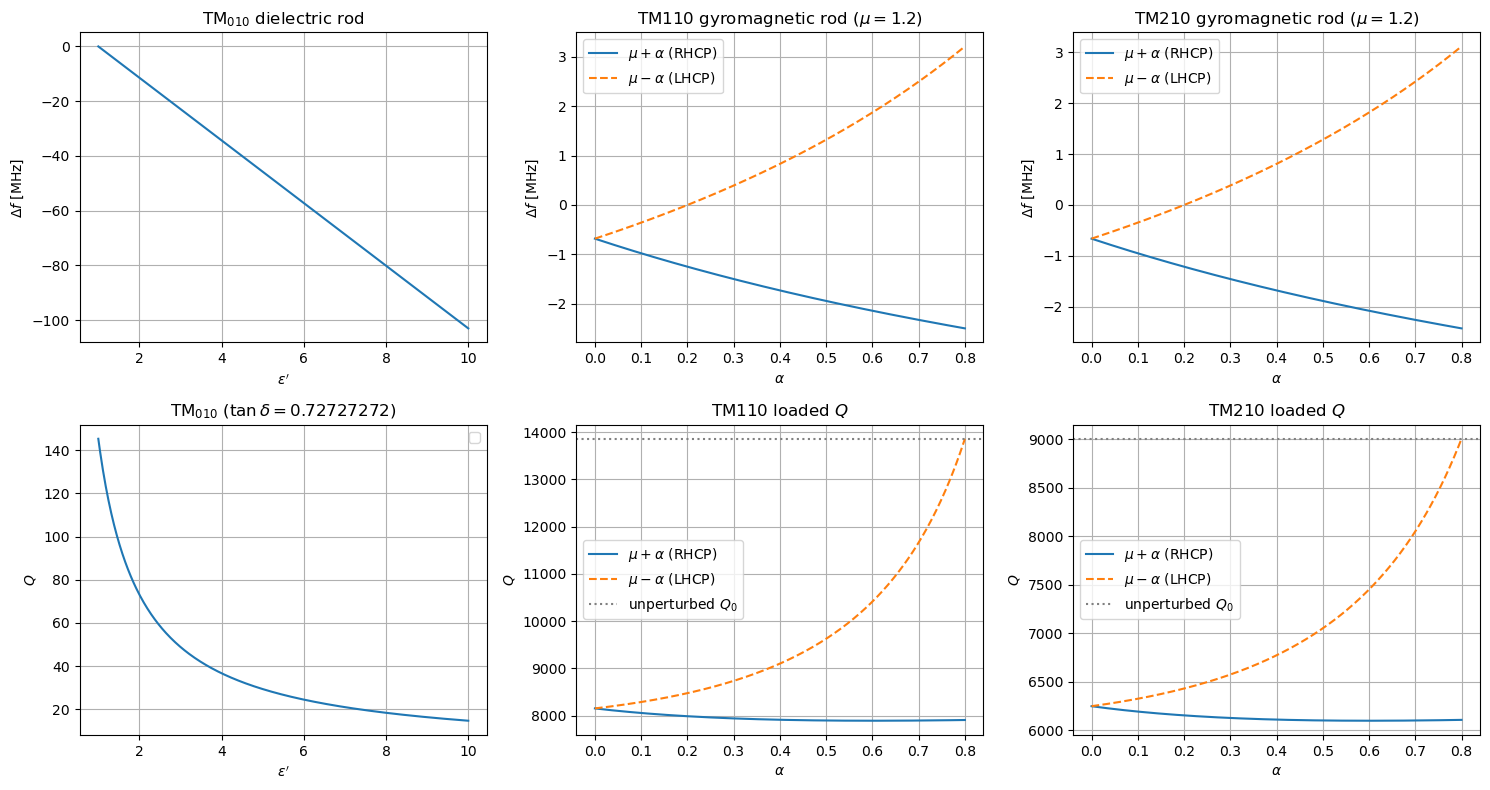

In [81]:
# ============================================================
# PARAMETER SWEEPS
# ============================================================
#
# TM010  : dielectric rod, sweep eps' at fixed loss tangent
# TM110  : gyromagnetic rod, sweep alpha at fixed mu, both CP senses
# TM210  : as TM110
# ============================================================

# Dielectric sweep
tan_delta = 0.72727272
eps_prime_sweep = np.linspace(1.0, 10.0, 400)
eps_sweep = eps_prime_sweep * (1 - 1j*tan_delta)

S_010_sweep = shift_TM010(eps_sweep)
f_010_sweep, Q_010_sweep = perturbed(f0_010, Q0_010, S_010_sweep)

# Gyromagnetic sweep
mu_fixed = 1.2 - 0.02j
alpha_sweep = np.linspace(0.0, 0.8, 400)
alpha_complex = alpha_sweep * (1 - 0.025j)

sweeps_mag = {}
for name, fn, f0_v, Q0_v in [
    ("TM110", shift_TM110, f0_110, Q0_110),
    ("TM210", shift_TM210, f0_210, Q0_210),
]:
    entry = {}
    for sense in (+1, -1):
        S = fn(mu_fixed, alpha_complex, sense)
        f_s, Q_s = perturbed(f0_v, Q0_v, S)
        entry[sense] = (f_s - f0_v, Q_s)
    sweeps_mag[name] = entry

fig, axs = plt.subplots(2, 3, figsize=(15, 8))

# --- TM010 ---
axs[0, 0].plot(eps_prime_sweep, (f_010_sweep - f0_010)/1e6)
axs[0, 0].set_xlabel(r"$\varepsilon'$")
axs[0, 0].set_ylabel(r"$\Delta f$ [MHz]")
axs[0, 0].set_title(r"TM$_{010}$ dielectric rod")
axs[0, 0].grid(True)

axs[1, 0].plot(eps_prime_sweep, Q_010_sweep)
#axs[1, 0].axhline(Q0_010, ls='--', color='grey', label=r'unperturbed $Q_0$')
axs[1, 0].set_xlabel(r"$\varepsilon'$")
axs[1, 0].set_ylabel(r"$Q$")
axs[1, 0].set_title(rf"TM$_{{010}}$ ($\tan\delta={tan_delta}$)")
axs[1, 0].grid(True)
axs[1, 0].legend()

# --- TM110 / TM210 ---
for col, name in [(1, "TM110"), (2, "TM210")]:
    for sense, style in [(+1, '-'), (-1, '--')]:
        df_s, Q_s = sweeps_mag[name][sense]
        lbl = r'$\mu+\alpha$ (RHCP)' if sense == +1 else r'$\mu-\alpha$ (LHCP)'
        axs[0, col].plot(alpha_sweep, df_s/1e6, style, label=lbl)
        axs[1, col].plot(alpha_sweep, Q_s, style, label=lbl)

    Q0_v = Q0_110 if name == "TM110" else Q0_210
    axs[0, col].set_xlabel(r"$\alpha$")
    axs[0, col].set_ylabel(r"$\Delta f$ [MHz]")
    axs[0, col].set_title(rf"{name} gyromagnetic rod ($\mu={mu_fixed.real}$)")
    axs[0, col].grid(True)
    axs[0, col].legend()

    axs[1, col].axhline(Q0_v, ls=':', color='grey', label=r'unperturbed $Q_0$')
    axs[1, col].set_xlabel(r"$\alpha$")
    axs[1, col].set_ylabel(r"$Q$")
    axs[1, col].set_title(f"{name} loaded $Q$")
    axs[1, col].grid(True)
    axs[1, col].legend()

plt.tight_layout()
plt.show()



### CP splitting

$$\frac{\Delta f_{\rm split}}{f_0}
= -C\,\frac{V_1}{V_0}\left[\frac{\mu+\alpha-1}{\mu+\alpha+1}-\frac{\mu-\alpha-1}{\mu-\alpha+1}\right]
= -C\,\frac{V_1}{V_0}\cdot\frac{4\alpha}{(\mu+1)^2-\alpha^2}$$


Self-check passed: CP splitting closed form matches the difference of the two branches.


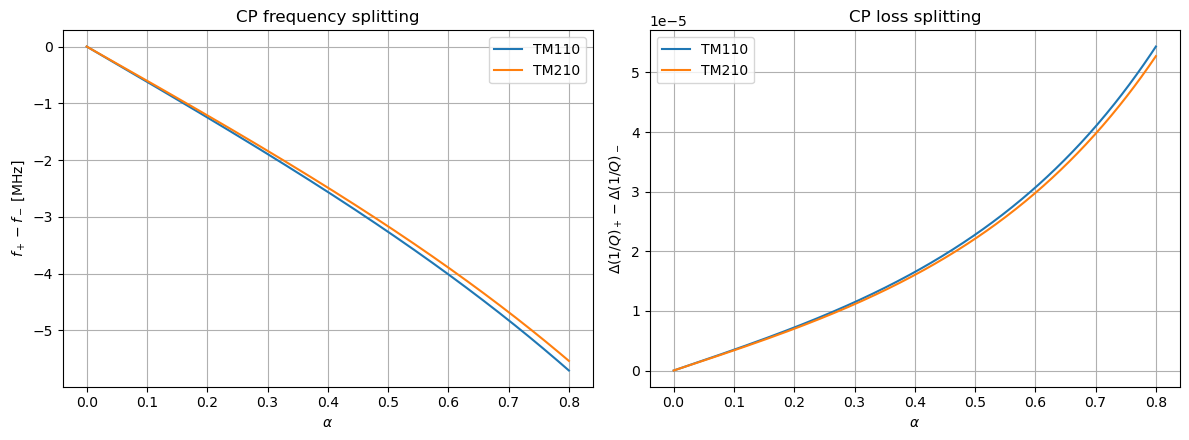

In [82]:
# ============================================================
# CIRCULAR-POLARISATION MODE SPLITTING
# ============================================================
#
# The two CP senses see mu +- alpha, so the degenerate pair
# splits. Subtracting the two shifts gives a closed form in
# which the gyrotropic term alpha appears on its own:
#
#   X(+) - X(-) = 4*alpha / ((mu + 1)^2 - alpha^2)
#
# so the splitting is first-order in alpha and vanishes when
# the sample is not gyrotropic -- this is the quantity the
# tensor-permeability measurement actually reads.
# ============================================================

display(Markdown(r"""
### CP splitting

$$\frac{\Delta f_{\rm split}}{f_0}
= -C\,\frac{V_1}{V_0}\left[\frac{\mu+\alpha-1}{\mu+\alpha+1}-\frac{\mu-\alpha-1}{\mu-\alpha+1}\right]
= -C\,\frac{V_1}{V_0}\cdot\frac{4\alpha}{(\mu+1)^2-\alpha^2}$$
"""))


def split_closed_form(coeff, vol_ratio, mu_r, alpha):
    """Closed-form CP splitting, S(+) - S(-)."""
    return -coeff * vol_ratio * 4*alpha / ((mu_r + 1)**2 - alpha**2)


# Verify the closed form against the difference of the two branches
for coeff, vol_ratio, fn in [
    (coeff_110, vol_ratio_110, shift_TM110),
    (coeff_210, vol_ratio_210, shift_TM210),
]:
    direct = fn(mu_fixed, alpha_complex, +1) - fn(mu_fixed, alpha_complex, -1)
    closed = split_closed_form(coeff, vol_ratio, mu_fixed, alpha_complex)
    assert np.allclose(direct, closed), "CP splitting closed form does not match"

print("Self-check passed: CP splitting closed form matches the difference of the two branches.")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))

for name, coeff, vol_ratio, f0_v, Q0_v in [
    ("TM110", coeff_110, vol_ratio_110, f0_110, Q0_110),
    ("TM210", coeff_210, vol_ratio_210, f0_210, Q0_210),
]:
    S_split = split_closed_form(coeff, vol_ratio, mu_fixed, alpha_complex)
    axs[0].plot(alpha_sweep, f0_v*np.real(S_split)/1e6, label=name)
    axs[1].plot(alpha_sweep, 2*np.imag(S_split), label=name)

axs[0].set_xlabel(r"$\alpha$")
axs[0].set_ylabel(r"$f_+ - f_-$ [MHz]")
axs[0].set_title("CP frequency splitting")
axs[0].grid(True)
axs[0].legend()

axs[1].set_xlabel(r"$\alpha$")
axs[1].set_ylabel(r"$\Delta(1/Q)_+ - \Delta(1/Q)_-$")
axs[1].set_title("CP loss splitting")
axs[1].grid(True)
axs[1].legend()

plt.tight_layout()
plt.show()


In [83]:
# ============================================================
# SUMMARY TABLE FOR A REPRESENTATIVE SAMPLE
# ============================================================

eps_sample = 3.0 - 0.03j        # dielectric rod (plastic-like)
mu_sample = 1.2 - 0.02j         # gyromagnetic rod
alpha_sample = 0.4 - 0.01j

rows = []

S = shift_TM010(eps_sample)
f_p, Q_p = perturbed(f0_010, Q0_010, S)
rows.append(("TM010", "-", f0_010, f_p, Q0_010, Q_p))

for name, fn, f0_v, Q0_v in [
    ("TM110", shift_TM110, f0_110, Q0_110),
    ("TM210", shift_TM210, f0_210, Q0_210),
]:
    for sense in (+1, -1):
        S = fn(mu_sample, alpha_sample, sense)
        f_p, Q_p = perturbed(f0_v, Q0_v, S)
        rows.append((name, f"mu{'+' if sense > 0 else '-'}alpha", f0_v, f_p, Q0_v, Q_p))

print(f"Sample: 10 mm rod, full height")
print(f"  dielectric   eps_r = {eps_sample}")
print(f"  gyromagnetic mu    = {mu_sample},  alpha = {alpha_sample}")
print()
header = f"{'cavity':8s} {'branch':12s} {'f0 [GHz]':>10s} {'f [GHz]':>10s} {'df [MHz]':>10s} {'Q0':>8s} {'Q':>8s}"
print(header)
print("-"*len(header))
for name, branch, f0_v, f_p, Q0_v, Q_p in rows:
    print(f"{name:8s} {branch:12s} {f0_v/1e9:10.6f} {f_p/1e9:10.6f} "
          f"{(f_p-f0_v)/1e6:10.3f} {Q0_v:8.0f} {Q_p:8.0f}")

print()
for name, coeff, vol_ratio, f0_v in [
    ("TM110", coeff_110, vol_ratio_110, f0_110),
    ("TM210", coeff_210, vol_ratio_210, f0_210),
]:
    S_split = split_closed_form(coeff, vol_ratio, mu_sample, alpha_sample)
    print(f"{name} CP splitting: {f0_v*np.real(S_split)/1e6:+.3f} MHz, "
          f"d(1/Q) splitting: {2*np.imag(S_split):+.3e}")


Sample: 10 mm rod, full height
  dielectric   eps_r = (3-0.03j)
  gyromagnetic mu    = (1.2-0.02j),  alpha = (0.4-0.01j)

cavity   branch         f0 [GHz]    f [GHz]   df [MHz]       Q0        Q
------------------------------------------------------------------------
TM010    -              2.450036   2.427147    -22.889    11655     2732
TM110    mu+alpha       2.450000   2.448271     -1.729    13862     7912
TM110    mu-alpha       2.450000   2.450832      0.832    13862     9101
TM210    mu+alpha       2.450007   2.448330     -1.678     9004     6108
TM210    mu-alpha       2.450007   2.450815      0.807     9004     6771

TM110 CP splitting: -2.561 MHz, d(1/Q) splitting: +1.652e-05
TM210 CP splitting: -2.485 MHz, d(1/Q) splitting: +1.603e-05
